# Diagnóstico de Câncer de Mama com Aprendizado de Máquina
### Projeto Final SME0828 — Introdução à Ciência de Dados — ICMC-USP — Prof. Francisco Rodrigues

**Base de dados:** Breast Cancer Wisconsin (Diagnostic), WDBC. São 569 pacientes e 30 medidas dos núcleos das células, obtidas por punção aspirativa por agulha fina (FNA).

**Integrantes:**
- David Carlos Santos de Lima
- Gabriel de Laet Pereira
- Vitor Dias Ferreira
- Lucas Henrique Girasol
- Caio Cardoso

**Repositório:** https://github.com/Laet345/Deteccao_de_cancer

Este é o notebook final do grupo. Ele junta o trabalho de todos: preparação dos dados, estatística descritiva, análise exploratória, agrupamento, seleção de atributos, modelagem e a avaliação final no conjunto de teste.

**Sumário**
1. Introdução e pergunta
2. Carga e preparação dos dados
3. Estatística descritiva
4. Análise exploratória (EDA)
5. Agrupamento, PCA e t-SNE
6. Seleção de atributos
7. Modelagem supervisionada (resumo)
8. Avaliação no conjunto de teste
9. Discussão
10. Sumário e conclusões

## 1. Introdução e pergunta

Para investigar uma lesão na mama, os médicos podem retirar algumas células com uma agulha fina (punção aspirativa, ou FNA). As imagens dessas células são analisadas por computador, que mede o tamanho e a forma dos núcleos. Com essas medidas, queremos dizer se a lesão é **benigna** ou **maligna**.

Os dois erros possíveis não têm o mesmo peso:
- **Falso negativo:** a paciente tem câncer, mas o modelo diz que é benigno. O tratamento atrasa. É o erro mais grave.
- **Falso positivo:** a paciente não tem câncer, mas o modelo diz que é maligno. Ela faz exames extras, mas o erro é corrigido depois.

**Pergunta:** é possível prever se uma lesão é maligna ou benigna a partir das medidas das células, errando o mínimo possível nos falsos negativos?

**Como vamos julgar a resposta** (definido antes de olhar o teste): ROC-AUC acima de 0,98 e sensibilidade (proporção de cânceres que o modelo encontra) perto de 100%, sem perder muita especificidade (proporção de benignos que o modelo acerta).

**Organização.** Seguimos os 10 passos do enunciado:

| Passo do enunciado | Onde está |
| :--- | :--- |
| 1. Preparar os dados | Seção 2 |
| 2. Descrição estatística | Seção 3 |
| 3. Padrões relevantes | Seção 4 |
| 4. Tipo de problema | Seções 1 e 5 (classificação binária, com agrupamento como estudo complementar) |
| 5. Métodos e ajuste dos modelos | Seção 7 |
| 6. Comparar com várias métricas | Seção 8 |
| 7. Projeção, seleção de atributos e transformações | Seções 5, 6 e 7 |
| 8. Resultados finais | Seções 8 e 10 |
| 9. Discussão | Seção 9 |
| 10. Sumário | Seção 10 |

**Cuidado com vazamento de dados.** Separamos treino (80%) e teste (20%) antes de qualquer ajuste, com `random_state=42`. Padronização, PCA, seleção de atributos e hiperparâmetros usam só o treino. O teste (114 pacientes, 42 malignos) só aparece na Seção 8, e nenhuma escolha foi feita olhando para ele.

**Quem fez o quê.** Lucas (preparação dos dados), Caio (estatística descritiva e EDA), Gabriel (agrupamento, PCA, t-SNE e seleção de atributos), Vitor (modelagem e validação cruzada) e David (avaliação final, discussão e sumário). Os notebooks de cada um continuam em `notebooks/`; aqui o código foi reunido para dar para ler tudo de uma vez.

### Preparação do ambiente

Importamos as bibliotecas, fixamos a semente aleatória (para os resultados se repetirem) e definimos o estilo dos gráficos. As tabelas e figuras novas são salvas em `results/` e `results/figuras/`. Os arquivos feitos antes pelos outros integrantes não são sobrescritos.

In [1]:
import platform
import warnings
from functools import partial
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from scipy import stats

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, f_classif, mutual_info_classif
from sklearn.manifold import TSNE
from sklearn.metrics import (
    average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.preprocessing import StandardScaler

# Avisos de obsolescência vindos dos modelos salvos (as versões ficam registradas abaixo)
warnings.filterwarnings("ignore", message=".*`probability` parameter was deprecated.*", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*'penalty' was deprecated.*", category=FutureWarning)
warnings.filterwarnings("ignore", message="Inconsistent values: penalty=", category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Tema escuro dos gráficos (o mesmo usado pelo grupo)
plt.style.use("dark_background")
sns.set_theme(style="darkgrid", rc={
    "axes.facecolor": "#1e1e1e", "figure.facecolor": "#121212", "grid.color": "#333333",
    "text.color": "white", "axes.labelcolor": "white", "xtick.color": "white",
    "ytick.color": "white", "axes.edgecolor": "white", "savefig.facecolor": "#121212",
})
COR_B, COR_M = "#4c9be8", "#ef5350"          # benigno, maligno
PALETA_CLASSE = {"Benigno": COR_B, "Maligno": COR_M}

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PASTA_RAW = BASE_DIR / "data" / "raw"
PASTA_DADOS = BASE_DIR / "data" / "processed"
PASTA_MODELOS = BASE_DIR / "models"
PASTA_RESULTADOS = BASE_DIR / "results"
PASTA_FIGURAS = PASTA_RESULTADOS / "figuras"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)


def salvar_fig(fig, nome):
    # Salva a figura em results/figuras/ e a exibe
    fig.savefig(PASTA_FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__}")

Python 3.13.9 | pandas 2.3.3 | numpy 2.3.4 | scikit-learn 1.9.1


## 2. Carga e preparação dos dados

O arquivo `wdbc.data` não tem cabeçalho, então colocamos os nomes das 32 colunas (`id`, `diagnosis` e 30 medidas). Depois checamos valores faltantes, duplicatas e tipos, tiramos o `id` (ele só identifica a paciente) e trocamos o diagnóstico por números (0 = benigno, 1 = maligno). No fim, conferimos que o resultado é igual ao `wdbc_limpo.csv` feito pelo Lucas.

In [2]:
base_medidas = ["radius", "texture", "perimeter", "area", "smoothness",
                "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
colunas = ["id", "diagnosis"] + [f"{m}_{s}" for s in ["mean", "se", "worst"] for m in base_medidas]

df_bruto = pd.read_csv(PASTA_RAW / "wdbc.data", header=None, names=colunas)
print("Dimensões do arquivo bruto:", df_bruto.shape)

# Integridade: faltantes, duplicatas, IDs repetidos e tipos
print("Valores faltantes (total):", int(df_bruto.isna().sum().sum()))
print("Linhas duplicadas:", int(df_bruto.duplicated().sum()))
print("IDs repetidos:", int(df_bruto["id"].duplicated().sum()))
tipos = df_bruto.dtypes.astype(str).value_counts()
print("Tipos das colunas:", dict(tipos))
display(df_bruto["diagnosis"].value_counts().rename({"B": "B (benigno)", "M": "M (maligno)"}).to_frame("pacientes"))

Dimensões do arquivo bruto: (569, 32)
Valores faltantes (total): 0
Linhas duplicadas: 0
IDs repetidos: 0
Tipos das colunas: {'float64': np.int64(30), 'int64': np.int64(1), 'object': np.int64(1)}


,pacientes
diagnosis,
B (benigno),357
M (maligno),212


Conferido: a preparação reproduz exatamente data/processed/wdbc_limpo.csv.


,treino,teste,% maligno (treino),% maligno (teste)
diagnosis,,,,
Benigno (0),285,72,NaN,NaN
Maligno (1),170,42,37.4,36.8


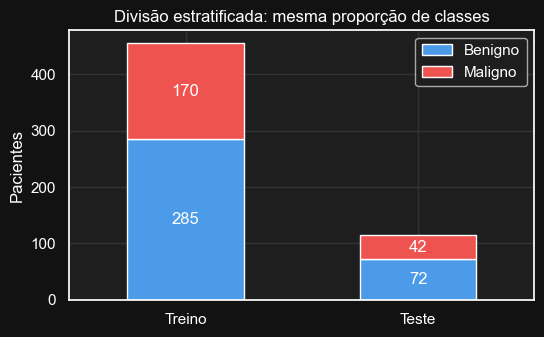

In [3]:
# Codificação do alvo e conferência com o arquivo processado pelo Lucas
df = df_bruto.copy()
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})
assert df["diagnosis"].notna().all()
pd.testing.assert_frame_equal(df, pd.read_csv(PASTA_DADOS / "wdbc_limpo.csv"))
print("Conferido: a preparação reproduz exatamente data/processed/wdbc_limpo.csv.")

# X (30 atributos, sem id) e y (0 = benigno, 1 = maligno), divisão estratificada 80/20
X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
assert (pd.read_csv(PASTA_DADOS / "y_train.csv")["diagnosis"].values == y_train.values).all()
assert (pd.read_csv(PASTA_DADOS / "y_test.csv")["diagnosis"].values == y_test.values).all()

resumo_split = pd.DataFrame({
    "treino": y_train.value_counts().sort_index(), "teste": y_test.value_counts().sort_index(),
}).rename(index={0: "Benigno (0)", 1: "Maligno (1)"})
resumo_split["% maligno (treino)"] = [None, round(100 * y_train.mean(), 1)]
resumo_split["% maligno (teste)"] = [None, round(100 * y_test.mean(), 1)]
display(resumo_split)

fig, ax = plt.subplots(figsize=(6, 3.5))
contagem = pd.DataFrame({"Treino": y_train.value_counts().sort_index(), "Teste": y_test.value_counts().sort_index()})
contagem.index = ["Benigno", "Maligno"]
contagem.T.plot.bar(stacked=True, color=[COR_B, COR_M], ax=ax, rot=0)
ax.set_ylabel("Pacientes"); ax.set_title("Divisão estratificada: mesma proporção de classes")
for c in ax.containers:
    ax.bar_label(c, label_type="center", color="white")
salvar_fig(fig, "01_divisao_treino_teste")

**Como interpretar:** o treino tem 455 pacientes (285 benignos e 170 malignos) e o teste tem 114 (72 e 42). A proporção de malignos é parecida nos dois (37,4% e 36,8%), e a divisão é a mesma usada pelo grupo todo. Não há valores faltantes nem duplicatas, e os 30 atributos são numéricos. As classes são um pouco desbalanceadas (cerca de 63% benignos). Não precisamos tratar isso, mas a acurácia sozinha não diz muito.

## 3. Estatística descritiva

Calculamos média, mediana, desvio padrão, assimetria e curtose dos 30 atributos, no geral e por classe. Para ver quais atributos separam melhor malignos de benignos, usamos o **d de Cohen**: quantos desvios padrão a média dos malignos está acima (ou abaixo) da dos benignos. Também contamos os valores extremos pela regra do IQR (fora de 1,5 × IQR dos quartis), só para observação.

In [4]:
desc = X.describe().T
desc["variância"] = X.var()
desc["IQR"] = desc["75%"] - desc["25%"]
desc["assimetria"] = X.skew()
desc["curtose"] = X.kurtosis()
print("--- Estatísticas descritivas gerais (569 pacientes) ---")
display(desc[["mean", "50%", "std", "variância", "IQR", "min", "max", "assimetria", "curtose"]]
        .rename(columns={"mean": "média", "50%": "mediana", "std": "desvio padrão", "min": "mín", "max": "máx"}).round(3))

--- Estatísticas descritivas gerais (569 pacientes) ---


,média,mediana,desvio padrão,variância,IQR,mín,máx,assimetria,curtose
radius_mean,14.127,13.370,3.524,12.419,4.080,6.981,28.110,0.942,0.846
texture_mean,19.290,18.840,4.301,18.499,5.630,9.710,39.280,0.650,0.758
perimeter_mean,91.969,86.240,24.299,590.440,28.930,43.790,188.500,0.991,0.972
area_mean,654.889,551.100,351.914,123843.554,362.400,143.500,2501.000,1.646,3.652
smoothness_mean,0.096,0.096,0.014,0.000,0.019,0.053,0.163,0.456,0.856
compactness_mean,0.104,0.093,0.053,0.003,0.065,0.019,0.345,1.190,1.650
concavity_mean,0.089,0.062,0.080,0.006,0.101,0.000,0.427,1.401,1.999
concave_points_mean,0.049,0.034,0.039,0.002,0.054,0.000,0.201,1.171,1.067
symmetry_mean,0.181,0.179,0.027,0.001,0.034,0.106,0.304,0.726,1.288
fractal_dimension_mean,0.063,0.062,0.007,0.000,0.008,0.050,0.097,1.304,3.006


,média (B),média (M),mediana (B),mediana (M),desvio (B),desvio (M),assimetria (B),assimetria (M),d de Cohen,extremos (IQR)
concave_points_worst,0.074,0.182,0.074,0.182,0.036,0.046,0.112,-0.093,2.693,0
perimeter_worst,87.006,141.370,86.920,138.000,13.527,29.457,0.009,0.748,2.598,15
concave_points_mean,0.026,0.088,0.023,0.086,0.016,0.034,0.925,0.739,2.545,10
radius_worst,13.380,21.135,13.350,20.590,1.981,4.284,-0.032,0.631,2.544,17
perimeter_mean,78.075,115.365,78.180,114.200,11.807,21.855,-0.065,0.605,2.290,13
area_worst,558.899,1422.286,547.400,1303.000,163.601,597.968,0.367,1.308,2.230,35
radius_mean,12.147,17.463,12.200,17.325,1.781,3.204,-0.084,0.502,2.205,14
area_mean,462.790,978.376,458.400,932.000,134.287,367.938,0.342,1.118,2.076,25
concavity_mean,0.046,0.161,0.037,0.151,0.043,0.075,3.473,0.902,2.003,18
concavity_worst,0.166,0.451,0.141,0.405,0.140,0.182,2.554,0.913,1.812,12


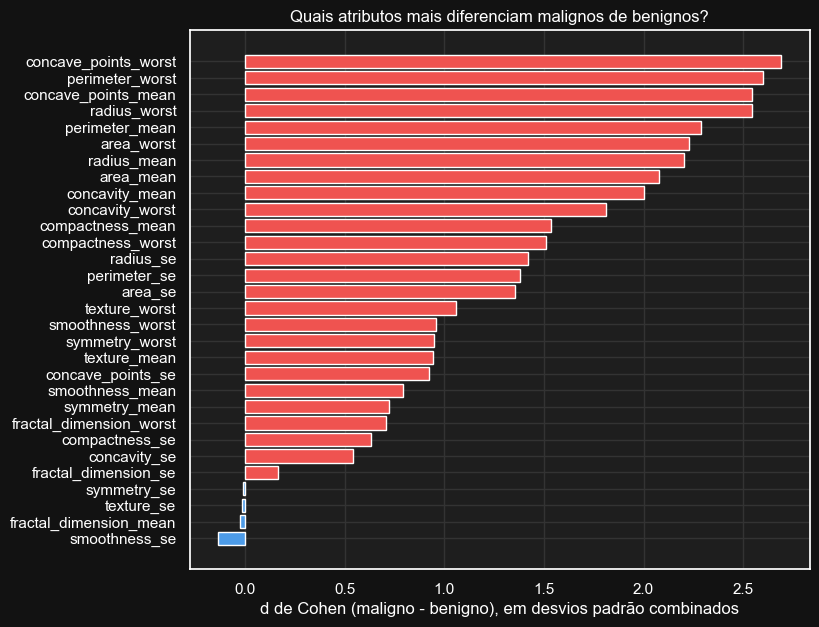

In [5]:
# Estatísticas por classe e tamanho do efeito (d de Cohen)
B_, M_ = X[y == 0], X[y == 1]
n1, n0 = len(M_), len(B_)
dp_comb = np.sqrt(((n1 - 1) * M_.var() + (n0 - 1) * B_.var()) / (n1 + n0 - 2))
por_classe = pd.DataFrame({
    "média (B)": B_.mean(), "média (M)": M_.mean(),
    "mediana (B)": B_.median(), "mediana (M)": M_.median(),
    "desvio (B)": B_.std(), "desvio (M)": M_.std(),
    "assimetria (B)": B_.skew(), "assimetria (M)": M_.skew(),
    "d de Cohen": (M_.mean() - B_.mean()) / dp_comb,
})
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
por_classe["extremos (IQR)"] = (X.lt(q1 - 1.5 * iqr) | X.gt(q3 + 1.5 * iqr)).sum()
por_classe = por_classe.sort_values("d de Cohen", ascending=False)
display(por_classe.round(3))

fig, ax = plt.subplots(figsize=(8, 7))
ordem = por_classe["d de Cohen"].sort_values()
ax.barh(ordem.index, ordem.values, color=[COR_M if v > 0 else COR_B for v in ordem.values])
ax.set_xlabel("d de Cohen (maligno - benigno), em desvios padrão combinados")
ax.set_title("Quais atributos mais diferenciam malignos de benignos?")
salvar_fig(fig, "02_cohen_d")

**Como interpretar:**
- Os tumores malignos têm núcleos maiores e mais irregulares. A área média, por exemplo, é 978 nos malignos e 463 nos benignos, e o raio médio é 17,5 contra 12,1.
- Os maiores *d* de Cohen são de `concave_points_worst` (2,69), `perimeter_worst` (2,60), `concave_points_mean` (2,55) e `radius_worst` (2,54). É uma diferença grande.
- Alguns atributos quase não diferenciam as classes (|*d*| < 0,2): `smoothness_se`, `fractal_dimension_mean`, `texture_se`, `symmetry_se` e `fractal_dimension_se`.
- Vários atributos, principalmente os de erro padrão (`_se`), têm distribuição bem assimétrica, com poucos valores muito altos. Isso é um motivo para padronizar os dados.
- Há muitos valores extremos (65 em `area_se` e 38 em `radius_se`). Como podem ser tumores mais agressivos de verdade, **não removemos**.

## 4. Análise exploratória (EDA)

Aqui procuramos padrões nos dados: (i) densidades e boxplots por classe dos 10 atributos de média; (ii) mapas de calor de correlação (Pearson e Spearman) e a lista de pares com |r| > 0,90; (iii) gráficos de dispersão (pairplots) com atributos que separam bem as classes.

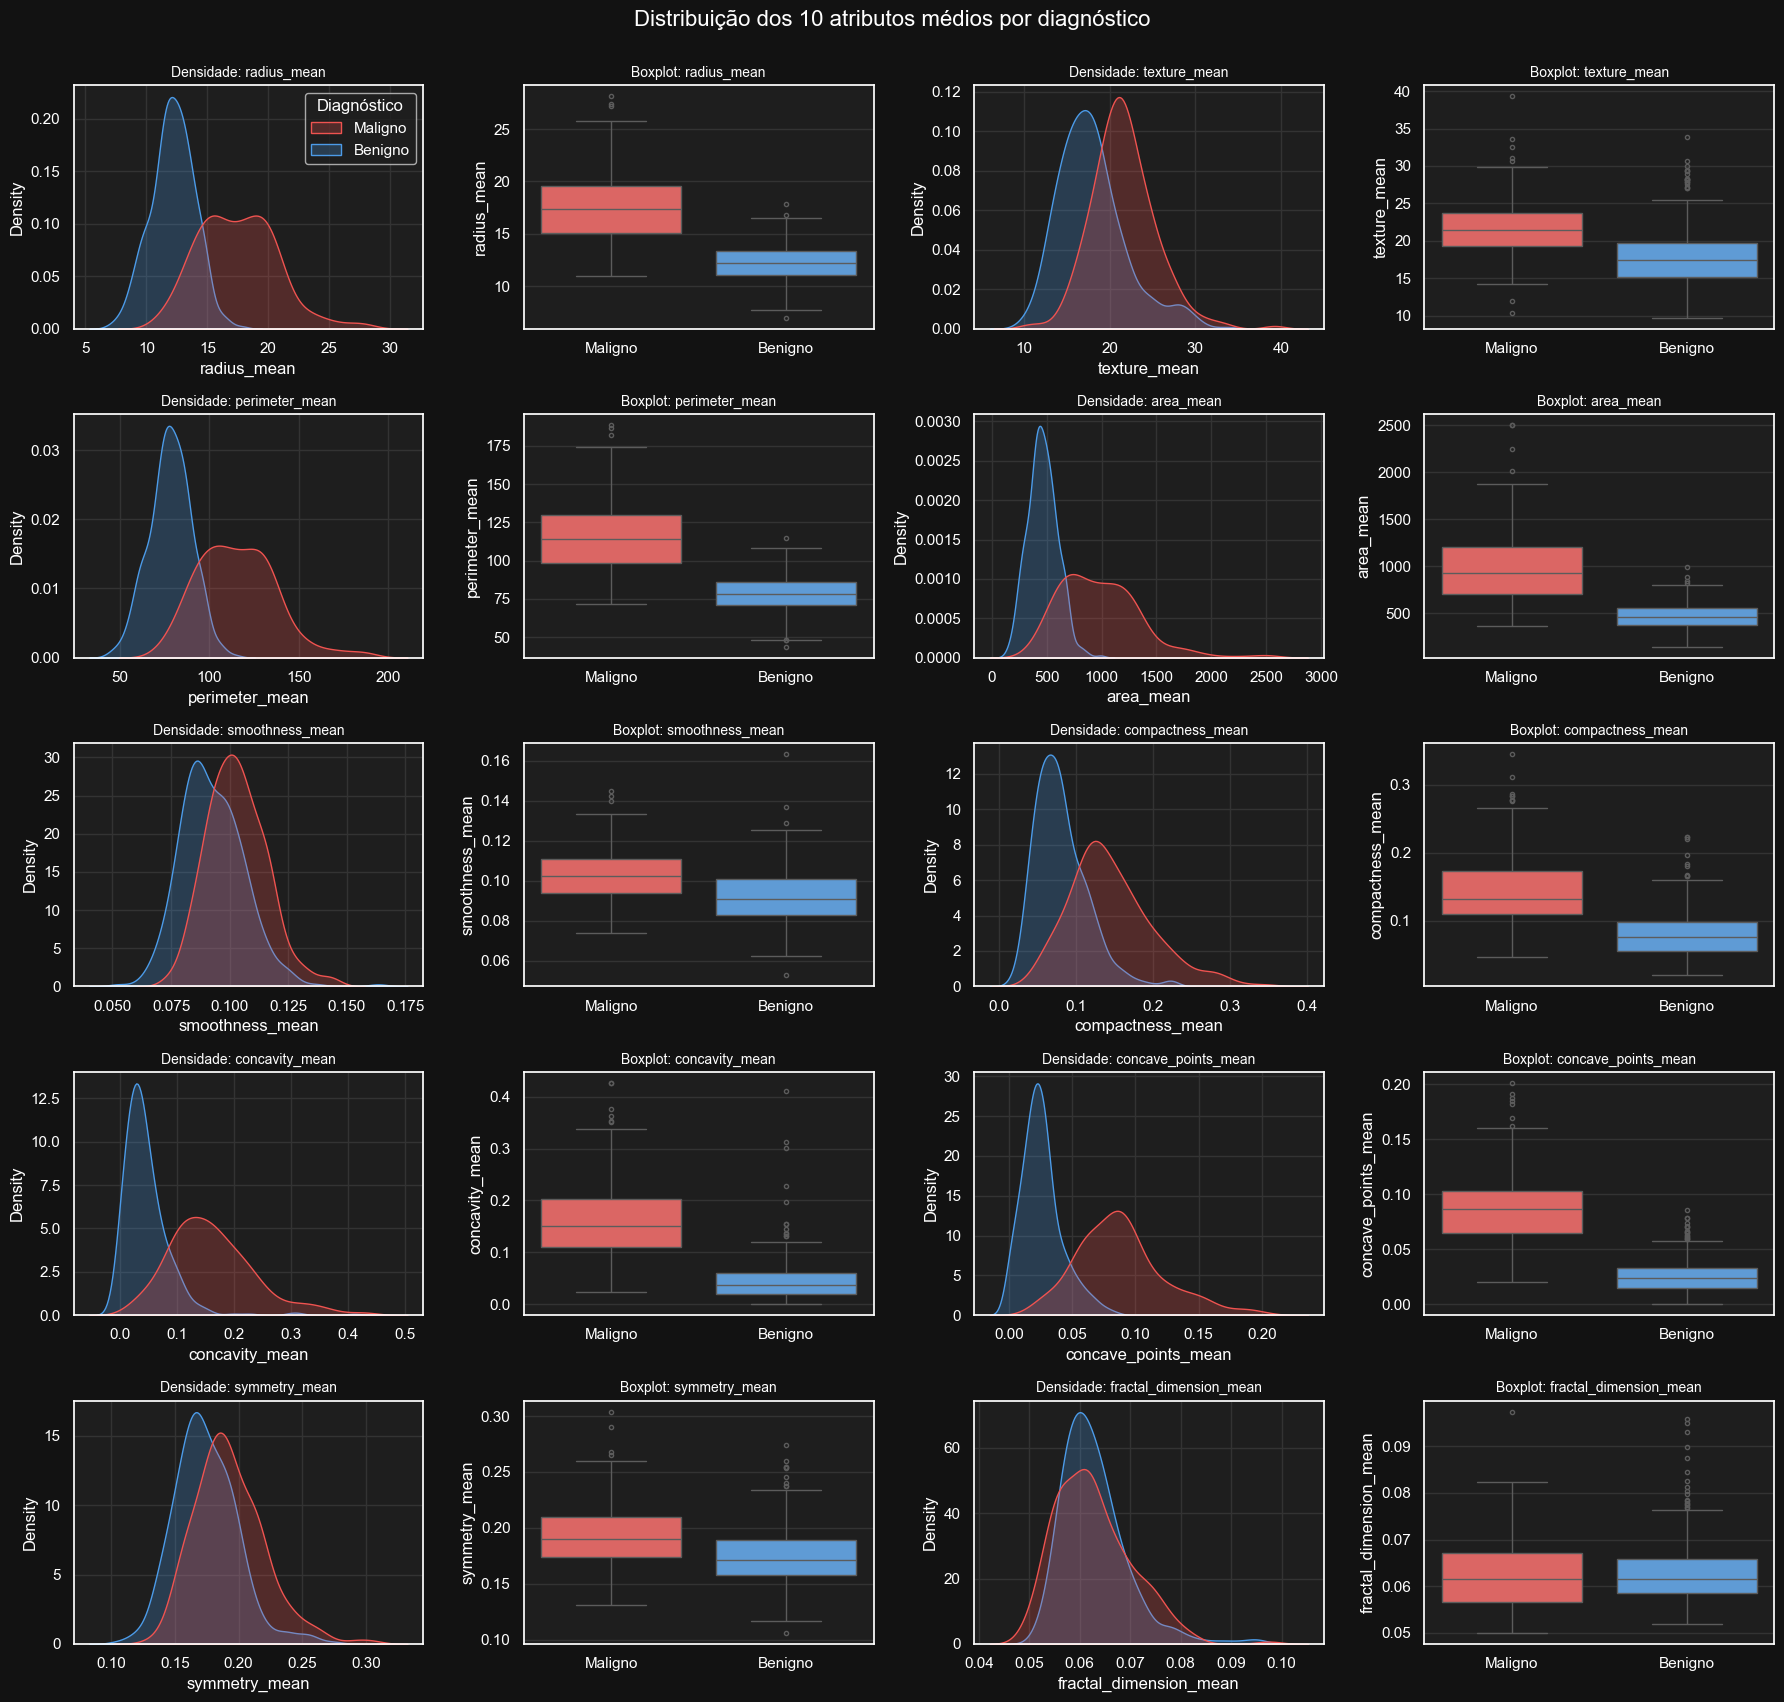

In [6]:
rot = y.map({0: "Benigno", 1: "Maligno"}).rename("Diagnóstico")
dados_eda = X.copy(); dados_eda["Diagnóstico"] = rot
features_mean = [c for c in X.columns if c.endswith("_mean")]

fig, axes = plt.subplots(5, 4, figsize=(18, 17))
for i, feat in enumerate(features_mean):
    r, c = divmod(i, 2)
    sns.kdeplot(data=dados_eda, x=feat, hue="Diagnóstico", fill=True, palette=PALETA_CLASSE,
                common_norm=False, ax=axes[r, 2 * c], legend=(i == 0))
    axes[r, 2 * c].set_title(f"Densidade: {feat}", fontsize=10)
    sns.boxplot(data=dados_eda, x="Diagnóstico", y=feat, hue="Diagnóstico", palette=PALETA_CLASSE,
                ax=axes[r, 2 * c + 1], legend=False, flierprops={"markersize": 3})
    axes[r, 2 * c + 1].set_title(f"Boxplot: {feat}", fontsize=10); axes[r, 2 * c + 1].set_xlabel("")
fig.suptitle("Distribuição dos 10 atributos médios por diagnóstico", fontsize=16, y=1.0)
plt.tight_layout()
salvar_fig(fig, "03_kde_boxplot_mean")

**Como interpretar:** em raio, perímetro, área, concavidade e pontos côncavos, a curva dos malignos fica bem deslocada para a direita e quase não se sobrepõe à dos benignos. Em textura, suavidade e simetria o deslocamento é menor. Em `fractal_dimension_mean` as curvas quase coincidem, então esse atributo ajuda pouco sozinho.

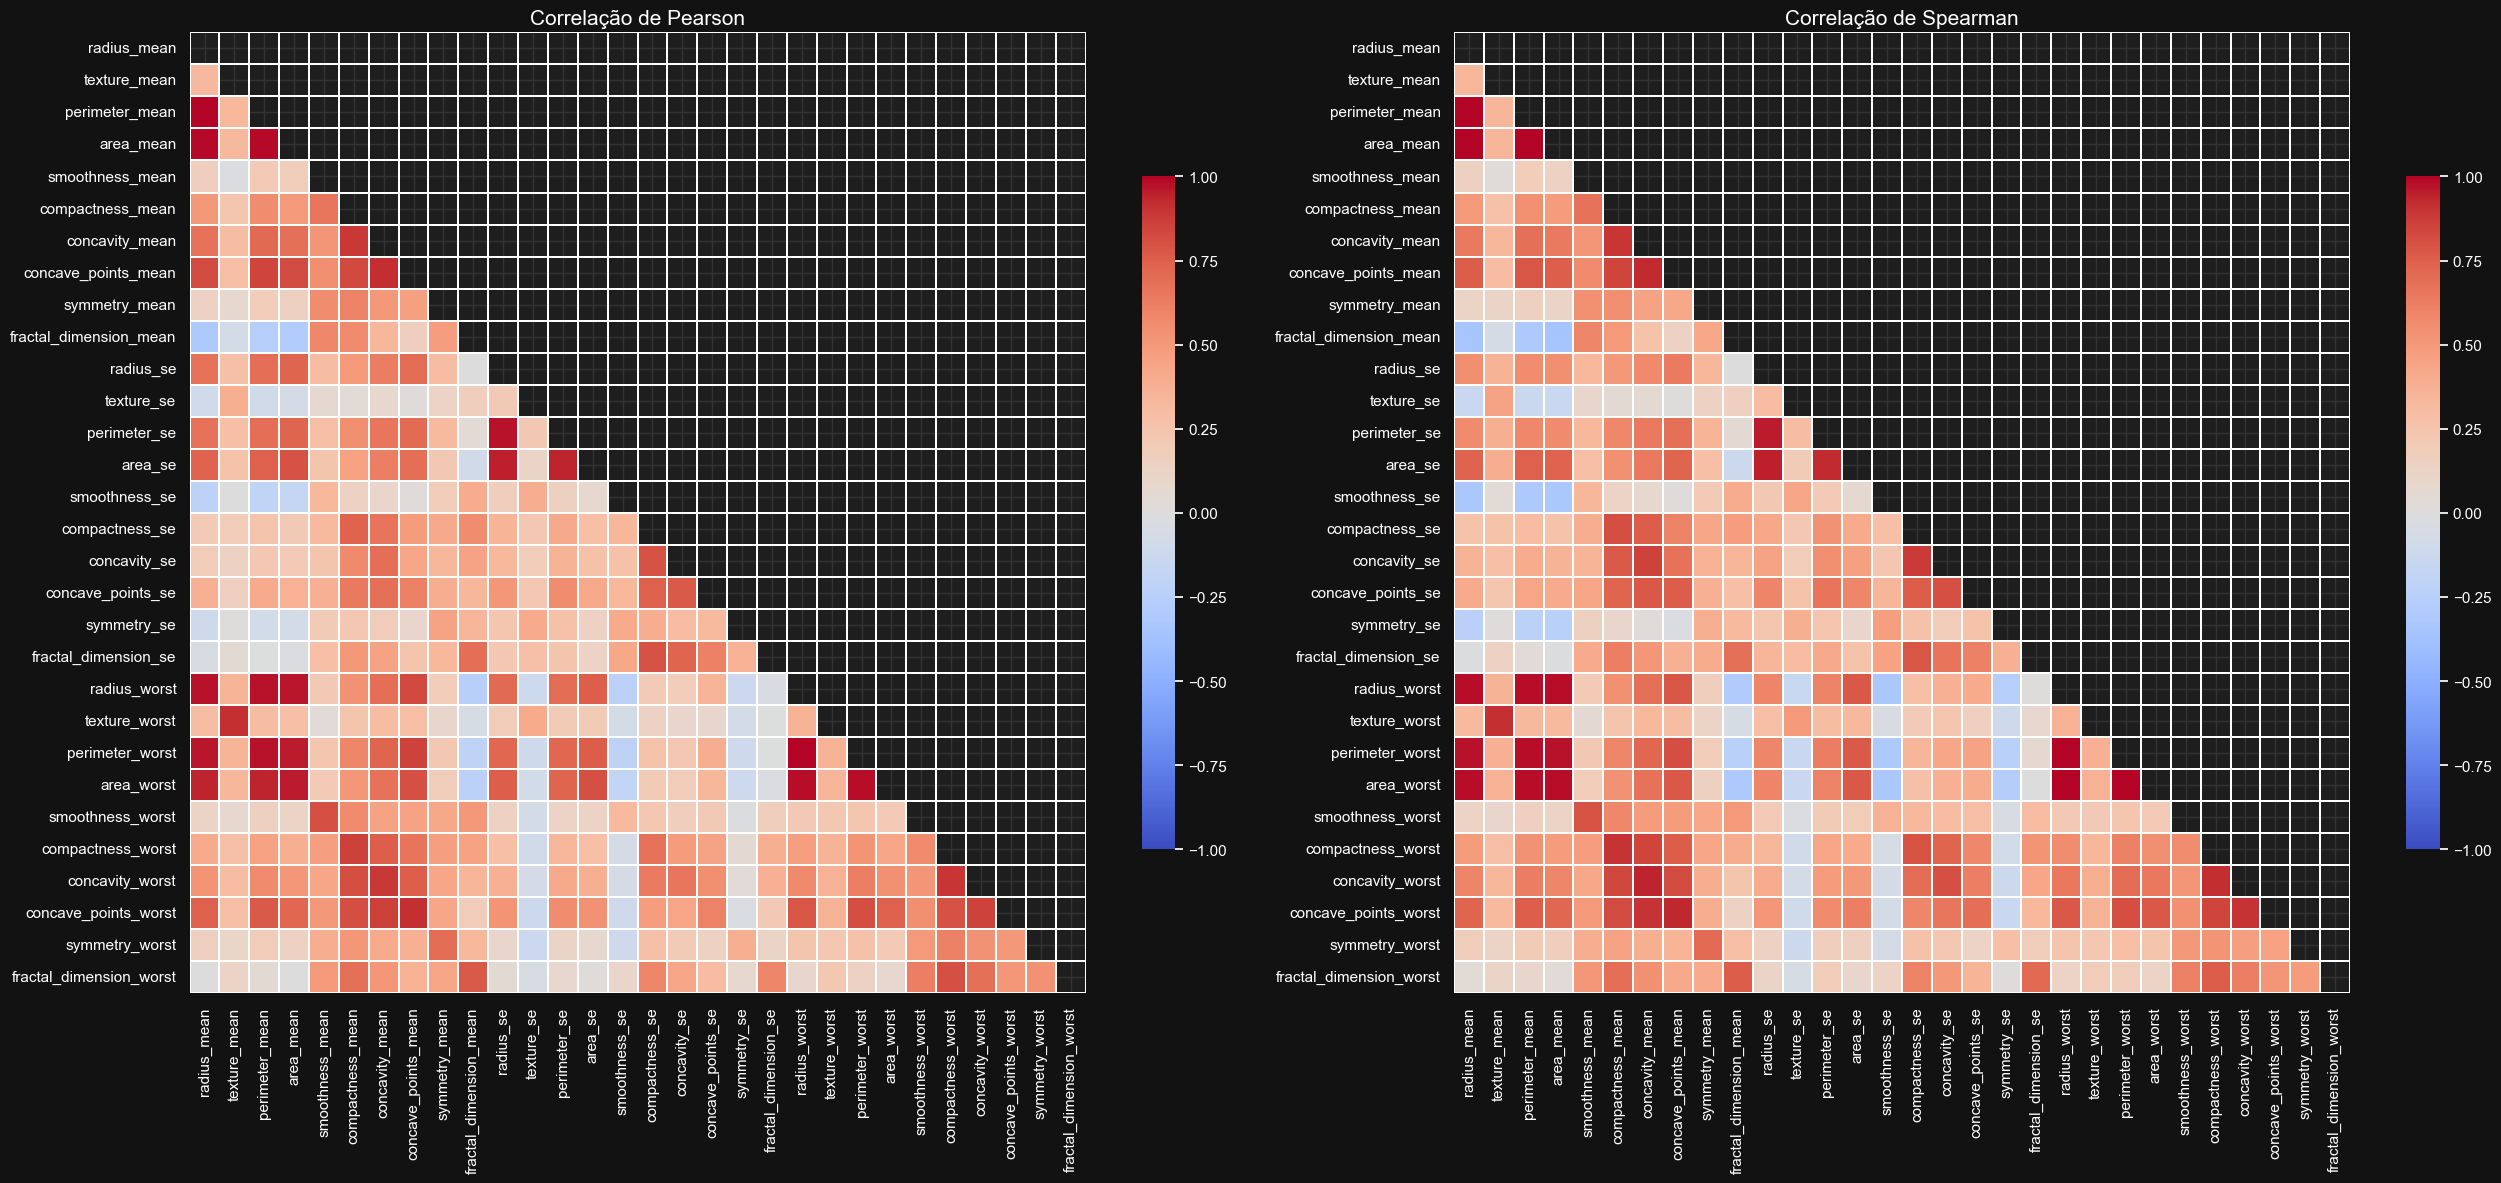

Pares com |r| > 0,90: 21 (de 435 possíveis)


,atributo 1,atributo 2,r
0,radius_mean,perimeter_mean,0.9979
1,radius_worst,perimeter_worst,0.9937
2,radius_mean,area_mean,0.9874
3,perimeter_mean,area_mean,0.9865
4,radius_worst,area_worst,0.9840
5,perimeter_worst,area_worst,0.9776
6,radius_se,perimeter_se,0.9728
7,perimeter_mean,perimeter_worst,0.9704
8,radius_mean,radius_worst,0.9695
9,perimeter_mean,radius_worst,0.9695


In [7]:
# Mapas de calor de correlação: Pearson e Spearman, lado a lado (triângulo inferior)
fig, axes = plt.subplots(1, 2, figsize=(26, 12))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    corr = X.corr(method=metodo)
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.3, ax=ax,
                cbar_kws={"shrink": 0.7})
    ax.set_title(f"Correlação de {metodo.capitalize()}", fontsize=15)
plt.tight_layout()
salvar_fig(fig, "04_heatmap_correlacao")

# Pares com |r| > 0,90 (Pearson)
corr_p = X.corr()
sup = corr_p.where(np.triu(np.ones(corr_p.shape), k=1).astype(bool))
pares = (sup.stack().rename("r").reset_index().rename(columns={"level_0": "atributo 1", "level_1": "atributo 2"}))
pares_altos = pares[pares["r"].abs() > 0.90].sort_values("r", key=abs, ascending=False)
print(f"Pares com |r| > 0,90: {len(pares_altos)} (de {len(pares)} possíveis)")
display(pares_altos.head(15).round(4).reset_index(drop=True))

**Como interpretar:** há **21 pares com |r| > 0,90** (de 435 possíveis), a maioria entre medidas de tamanho, como `radius_mean` e `perimeter_mean` (0,998). Faz sentido, porque perímetro e área dependem do raio. Pearson e Spearman mostram o mesmo padrão. Ou seja, muitos atributos trazem a mesma informação (multicolinearidade). Isso atrapalha a leitura dos coeficientes de modelos lineares e é um motivo para reduzir a dimensão (Seções 5 e 6).

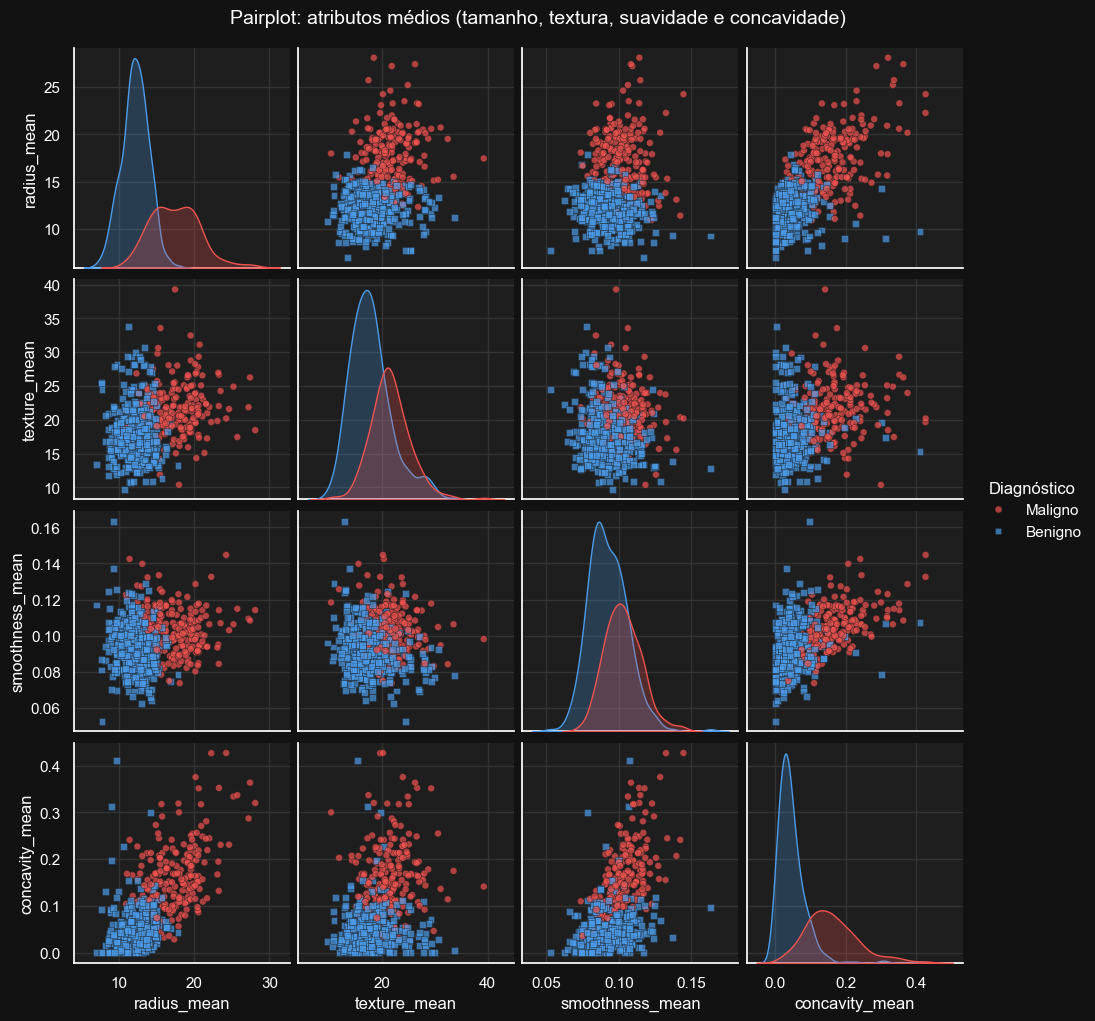

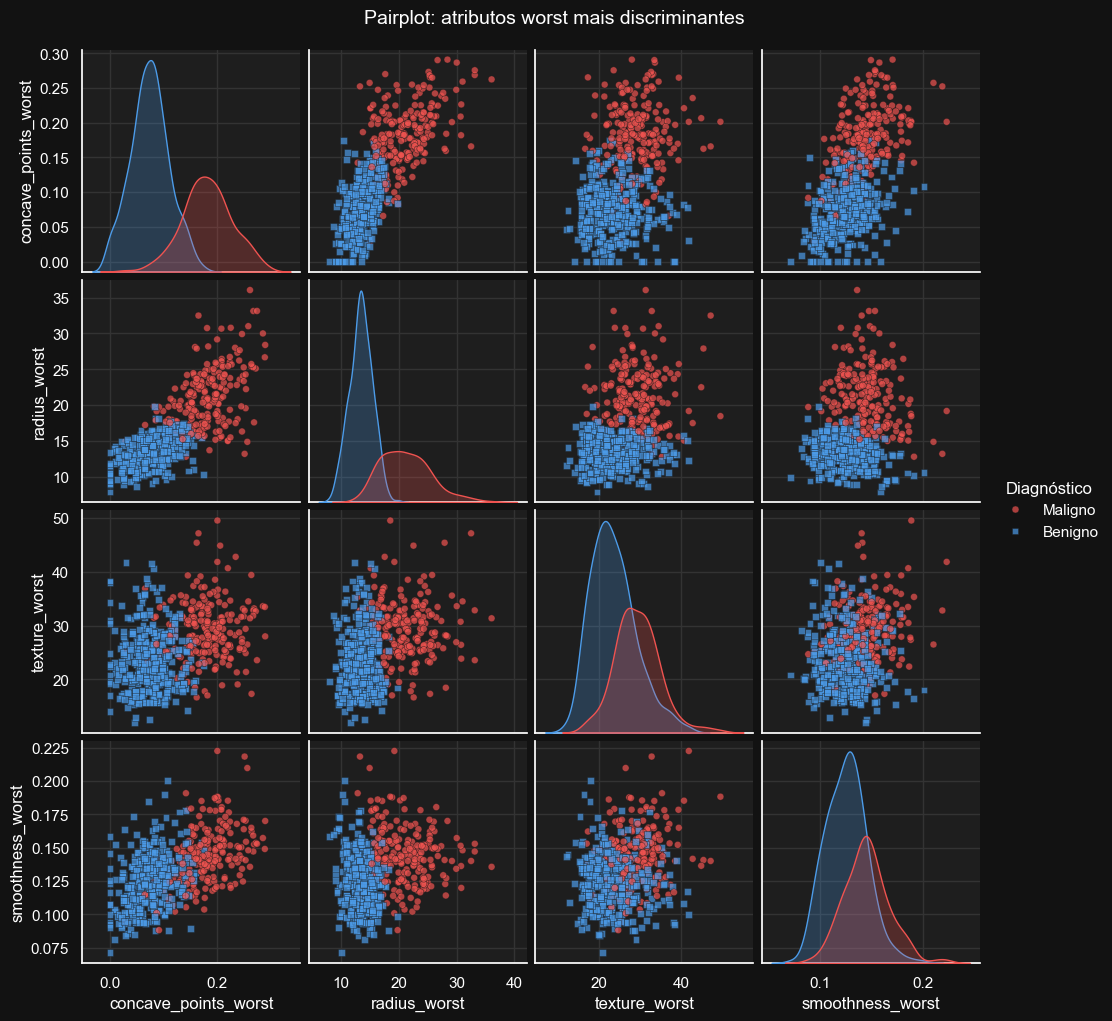

In [8]:
# Pairplot 1: atributos médios escolhidos pelo grupo (tamanho, textura, suavidade e forma)
sel1 = ["radius_mean", "texture_mean", "smoothness_mean", "concavity_mean"]
g = sns.pairplot(dados_eda[sel1 + ["Diagnóstico"]], hue="Diagnóstico", palette=PALETA_CLASSE,
                 markers=["o", "s"], plot_kws={"alpha": 0.7, "edgecolor": "k", "s": 25}, corner=False)
g.figure.suptitle("Pairplot: atributos médios (tamanho, textura, suavidade e concavidade)", y=1.02, fontsize=14)
g.figure.savefig(PASTA_FIGURAS / "05_pairplot_mean.png", dpi=130, bbox_inches="tight")
plt.show()

# Pairplot 2: os atributos worst mais discriminantes e pouco redundantes entre si
sel2 = ["concave_points_worst", "radius_worst", "texture_worst", "smoothness_worst"]
g = sns.pairplot(dados_eda[sel2 + ["Diagnóstico"]], hue="Diagnóstico", palette=PALETA_CLASSE,
                 markers=["o", "s"], plot_kws={"alpha": 0.7, "edgecolor": "k", "s": 25})
g.figure.suptitle("Pairplot: atributos worst mais discriminantes", y=1.02, fontsize=14)
g.figure.savefig(PASTA_FIGURAS / "06_pairplot_worst.png", dpi=130, bbox_inches="tight")
plt.show()

**Como interpretar:** `radius_worst` e `concave_points_worst` separam bem as classes e, juntos, deixam só uma faixa pequena de sobreposição. `texture_worst` e `smoothness_worst` não separam sozinhos, mas acrescentam informação (os malignos têm valores um pouco maiores). Os pontos nessa região de sobreposição são os casos mais difíceis para os modelos (Seção 9.2).

## 5. Agrupamento, PCA e t-SNE

A partir daqui, tudo é ajustado só com o treino (455 pacientes), com os dados padronizados. Vamos ver: (i) se o K-Means e o GMM, sem usar o diagnóstico, formam dois grupos parecidos com benigno e maligno; (ii) o PCA, que resume os 30 atributos em poucos componentes; (iii) o t-SNE, outra projeção em 2D.

,Silhouette,Concordância com o diagnóstico
K-Means,0.343,0.908
GMM,0.314,0.934


Componentes para >= 85% / 90% / 95% da variância: 6 / 7 / 10


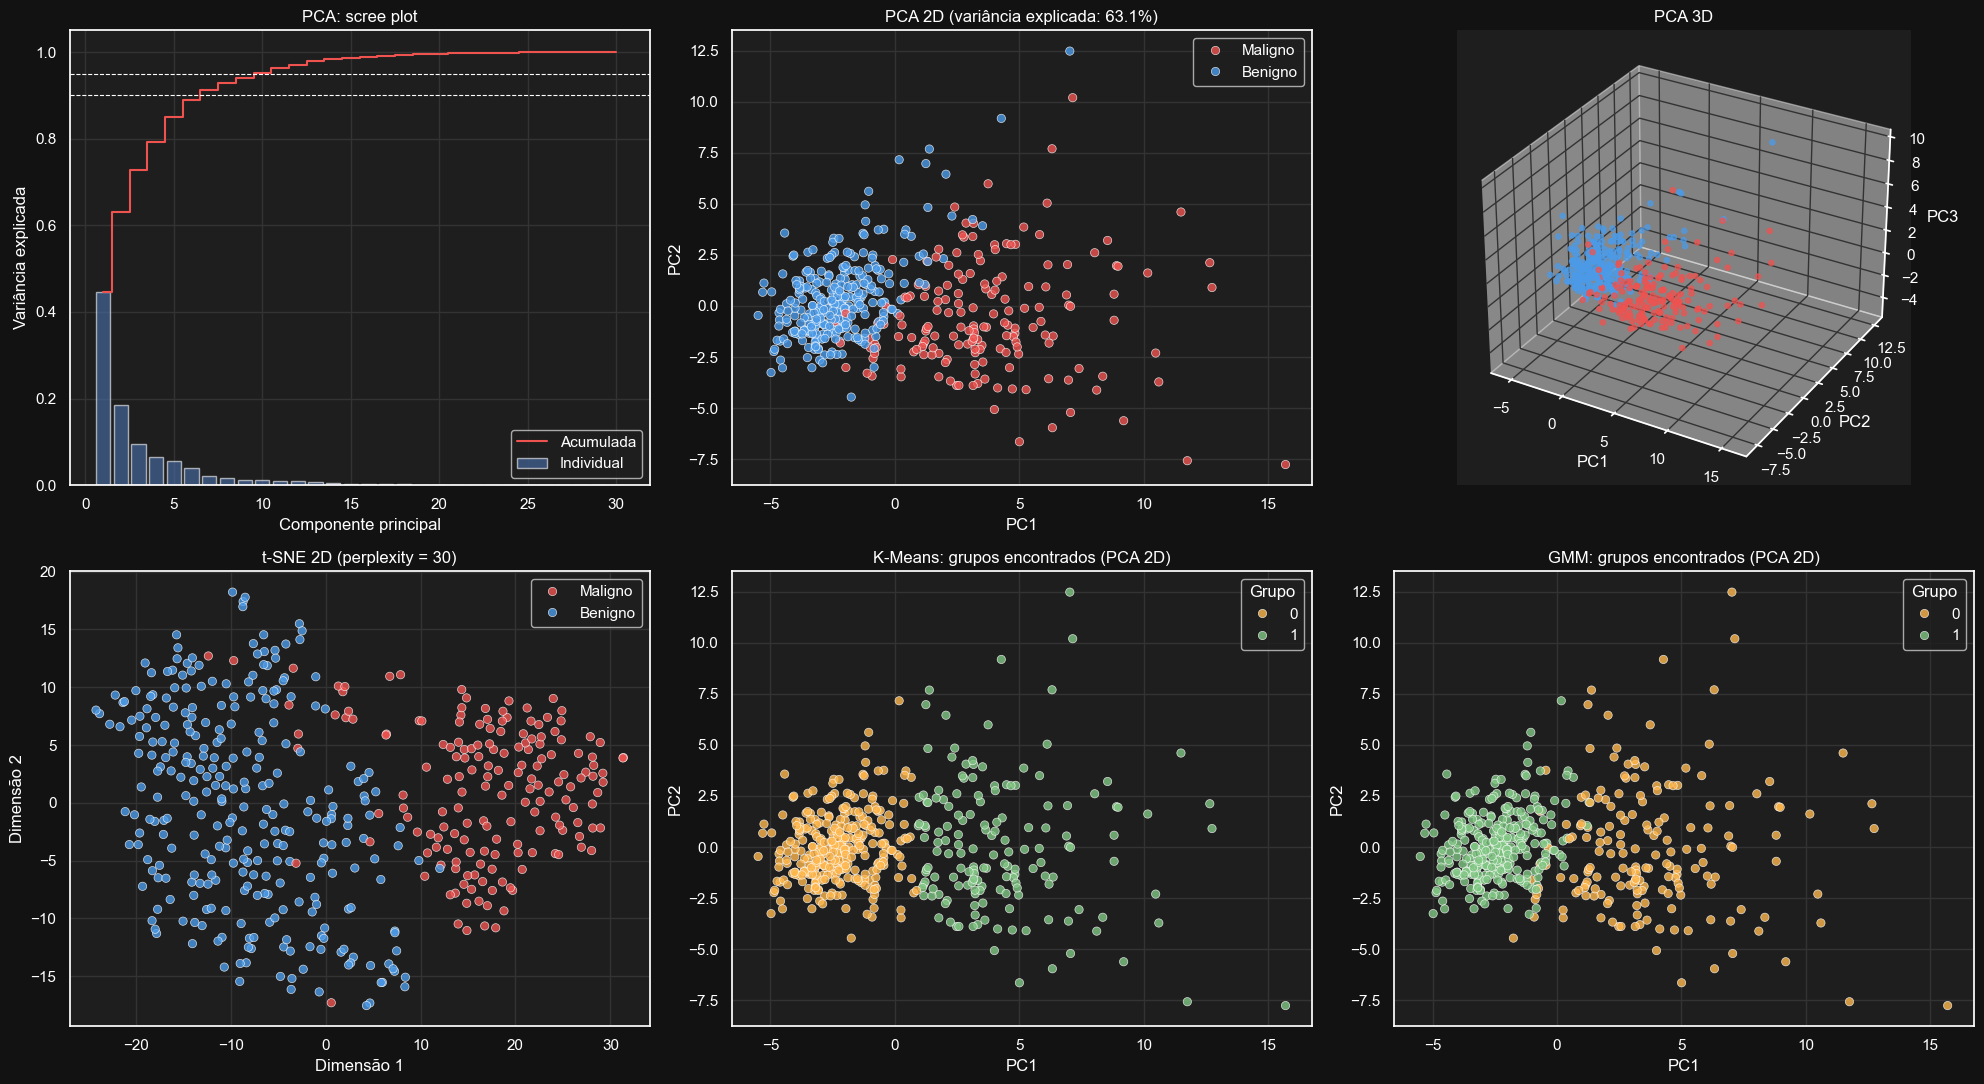

Contingência K-Means x diagnóstico real:


K-Means,0,1
Real,,
0,270,15
1,27,143


Contingência GMM x diagnóstico real:


GMM,0,1
Real,,
0,18,267
1,158,12


In [9]:
escala_treino = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(escala_treino.transform(X_train), columns=X.columns, index=X_train.index)
feature_names = X_train_scaled.columns
ytr = y_train.values

# --- Agrupamento sem rótulos ---
kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
lab_km = kmeans.fit_predict(X_train_scaled)
gmm = GaussianMixture(n_components=2, random_state=RANDOM_STATE)
lab_gmm = gmm.fit_predict(X_train_scaled)

def concordancia(rotulos):
    acerto = (rotulos == ytr).mean()
    return max(acerto, 1 - acerto)   # os números dos clusters são arbitrários

resumo_cluster = pd.DataFrame({
    "Silhouette": [silhouette_score(X_train_scaled, lab_km), silhouette_score(X_train_scaled, lab_gmm)],
    "Concordância com o diagnóstico": [concordancia(lab_km), concordancia(lab_gmm)],
}, index=["K-Means", "GMM"])
display(resumo_cluster.round(3))

# --- PCA ---
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_scaled)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
n85, n90, n95 = [int(np.argmax(var_acum >= v) + 1) for v in (0.85, 0.90, 0.95)]
print(f"Componentes para >= 85% / 90% / 95% da variância: {n85} / {n90} / {n95}")

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_scaled)
Z2 = pca_2d.transform(X_train_scaled)
pca_3d = PCA(n_components=3, random_state=RANDOM_STATE).fit(X_train_scaled)
Z3 = pca_3d.transform(X_train_scaled)

# --- t-SNE ---
X_tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, max_iter=1000).fit_transform(X_train_scaled)

rotulos = np.where(ytr == 0, "Benigno", "Maligno")
fig = plt.figure(figsize=(20, 11))
ax = fig.add_subplot(2, 3, 1)
ax.bar(range(1, 31), pca_full.explained_variance_ratio_, alpha=0.6, label="Individual")
ax.step(range(1, 31), var_acum, where="mid", color=COR_M, label="Acumulada")
for v in (0.90, 0.95):
    ax.axhline(v, color="white", ls="--", lw=0.8)
ax.set_xlabel("Componente principal"); ax.set_ylabel("Variância explicada"); ax.set_title("PCA: scree plot"); ax.legend()

ax = fig.add_subplot(2, 3, 2)
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=rotulos, palette=PALETA_CLASSE, alpha=0.8, ax=ax)
ax.set_title(f"PCA 2D (variância explicada: {pca_2d.explained_variance_ratio_.sum():.1%})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

ax = fig.add_subplot(2, 3, 3, projection="3d")
ax.scatter(Z3[:, 0], Z3[:, 1], Z3[:, 2], c=np.where(ytr == 1, COR_M, COR_B), alpha=0.7, s=14)
ax.set_title("PCA 3D"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")

ax = fig.add_subplot(2, 3, 4)
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=rotulos, palette=PALETA_CLASSE, alpha=0.8, ax=ax)
ax.set_title("t-SNE 2D (perplexity = 30)"); ax.set_xlabel("Dimensão 1"); ax.set_ylabel("Dimensão 2")

for pos, (rot_c, nome) in enumerate([(lab_km, "K-Means"), (lab_gmm, "GMM")], start=5):
    ax = fig.add_subplot(2, 3, pos)
    sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=rot_c, palette=["#ffb74d", "#81c784"], alpha=0.8, ax=ax)
    ax.set_title(f"{nome}: grupos encontrados (PCA 2D)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(title="Grupo")
plt.tight_layout()
salvar_fig(fig, "07_agrupamento_pca_tsne")

print("Contingência K-Means x diagnóstico real:")
display(pd.crosstab(pd.Series(ytr, name="Real"), pd.Series(lab_km, name="K-Means")))
print("Contingência GMM x diagnóstico real:")
display(pd.crosstab(pd.Series(ytr, name="Real"), pd.Series(lab_gmm, name="GMM")))

**Como interpretar:**
- **Agrupamento sem diagnóstico:** o K-Means concorda com o diagnóstico em 90,8% dos pacientes e o GMM em 93,4%. Os números dos grupos são arbitrários, por isso a tabela do GMM parece invertida. O *silhouette* é moderado (0,34 e 0,31): existem dois grupos, mas com sobreposição na fronteira.
- **PCA:** 7 componentes guardam 90% da variância (6 guardam 85% e 10 guardam 95%). Os dois primeiros (63,1%) já separam bem as classes.
- **t-SNE:** aparecem duas regiões distintas, com poucos pacientes misturados.
- Ou seja, os dados já são bem separáveis, e um modelo supervisionado deve ir ainda melhor.

## 6. Seleção de atributos

Usamos três métodos, só com o treino: (i) filtro de correlação (mantém um atributo só se |r| ≤ 0,85 com os já mantidos, começando pelos mais informativos segundo a Informação Mútua); (ii) ANOVA e Informação Mútua; (iii) RFE com Random Forest. A lista final, o **Top-10 não redundante**, é o cenário D da modelagem. Conferimos que ela é igual à do arquivo `wdbc_train_top10.csv`, feito pelo Gabriel.

Filtro de colinearidade (|r| > 0.85): 11 descartados, 19 mantidos
Top-10 não redundante (= wdbc_train_top10.csv): ['radius_worst', 'concave_points_mean', 'area_se', 'concavity_worst', 'compactness_mean', 'texture_worst', 'concave_points_se', 'symmetry_worst', 'smoothness_mean', 'smoothness_worst']


,ANOVA (F),Informação Mútua,RFE (Random Forest),Top-10 não redundante
0,concave_points_worst,radius_worst,radius_mean,radius_worst
1,perimeter_worst,perimeter_worst,perimeter_mean,concave_points_mean
2,radius_worst,area_worst,area_mean,area_se
3,concave_points_mean,concave_points_mean,concavity_mean,concavity_worst
4,perimeter_mean,concave_points_worst,concave_points_mean,compactness_mean
5,area_worst,perimeter_mean,radius_worst,texture_worst
6,radius_mean,area_mean,texture_worst,concave_points_se
7,area_mean,radius_mean,perimeter_worst,symmetry_worst
8,concavity_mean,concavity_mean,area_worst,smoothness_mean
9,concavity_worst,area_se,concave_points_worst,smoothness_worst


Atributos comuns aos três métodos brutos: 9 -> ['area_mean', 'area_worst', 'concave_points_mean', 'concave_points_worst', 'concavity_mean', 'perimeter_mean', 'perimeter_worst', 'radius_mean', 'radius_worst']


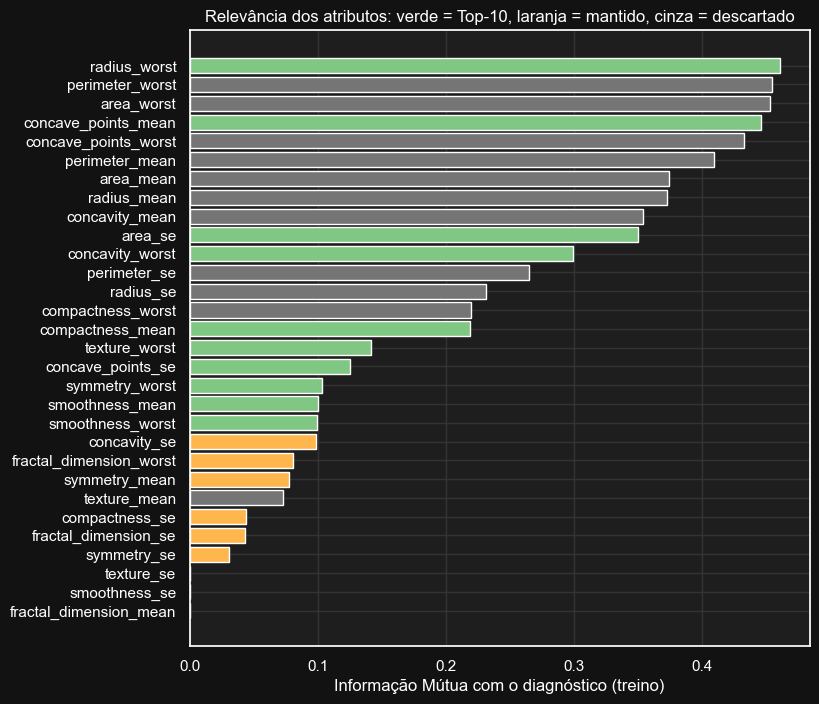

In [10]:
limiar_corr = 0.85
corr_abs = X_train_scaled.corr().abs()
relevancia = pd.Series(mutual_info_classif(X_train_scaled, ytr, random_state=RANDOM_STATE),
                       index=feature_names).sort_values(ascending=False)

mantidos = []
for f in relevancia.index:
    if all(corr_abs.loc[f, k] <= limiar_corr for k in mantidos):
        mantidos.append(f)
descartados = [c for c in feature_names if c not in mantidos]
print(f"Filtro de colinearidade (|r| > {limiar_corr}): {len(descartados)} descartados, {len(mantidos)} mantidos")

top10 = mantidos[:10]
assert top10 == list(pd.read_csv(PASTA_DADOS / "wdbc_train_top10.csv").columns), "Top-10 difere do arquivo do Gabriel"
print("Top-10 não redundante (= wdbc_train_top10.csv):", top10)

skb_f = SelectKBest(score_func=f_classif, k=10).fit(X_train_scaled, ytr)
skb_mi = SelectKBest(score_func=partial(mutual_info_classif, random_state=RANDOM_STATE), k=10).fit(X_train_scaled, ytr)
rank_f = pd.Series(skb_f.scores_, index=feature_names).sort_values(ascending=False)
rank_mi = pd.Series(skb_mi.scores_, index=feature_names).sort_values(ascending=False)
rfe_rf = RFE(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE), n_features_to_select=10).fit(X_train_scaled, ytr)
top_rfe = list(feature_names[rfe_rf.support_])

display(pd.DataFrame({"ANOVA (F)": rank_f.head(10).index, "Informação Mútua": rank_mi.head(10).index,
                      "RFE (Random Forest)": top_rfe, "Top-10 não redundante": top10}))
comuns = set(rank_f.head(10).index) & set(rank_mi.head(10).index) & set(top_rfe)
print(f"Atributos comuns aos três métodos brutos: {len(comuns)} -> {sorted(comuns)}")

fig, ax = plt.subplots(figsize=(8, 8))
rel = relevancia.sort_values()
ax.barh(rel.index, rel.values, color=[("#81c784" if f in top10 else ("#ffb74d" if f in mantidos else "#757575")) for f in rel.index])
ax.set_xlabel("Informação Mútua com o diagnóstico (treino)")
ax.set_title("Relevância dos atributos: verde = Top-10, laranja = mantido, cinza = descartado")
salvar_fig(fig, "08_selecao_atributos")

**Como interpretar:**
- O filtro de correlação descartou 11 atributos e manteve 19.
- ANOVA, Informação Mútua e RFE concordam bastante: 9 dos 10 atributos de cada um são os mesmos (raio, perímetro, área, concavidade e pontos côncavos). Só que esses atributos são muito correlacionados entre si.
- O Top-10 não redundante abre mão de um pouco do poder de cada atributo para ter mais variedade: tem tamanho, forma, textura, simetria e suavidade.
- Como essa lista foi escolhida com todo o treino, o cenário D pode ter uma pequena vantagem na validação cruzada (o Vitor mediu isso no notebook de modelagem).

## 7. Modelagem supervisionada

Foram treinados 7 classificadores: Regressão Logística, KNN, SVM Linear, SVM RBF, Naive Bayes, Árvore de Decisão e Random Forest (detalhes em `notebooks/modelagem_supervisionada.ipynb`). E validação cruzada com 10 partes e `GridSearchCV` para escolher os hiperparâmetros (métrica: ROC-AUC), em 4 cenários:
- **A:** os 30 atributos padronizados;
- **B:** PCA (90% ou 95% da variância);
- **C:** `SelectKBest`, com *k* escolhido na validação cruzada;
- **D:** Top-10 não redundante (Seção 6).

Padronização, PCA e seleção ficam dentro do *pipeline* e são refeitos a cada parte da validação cruzada, para não vazar informação. Os 28 modelos prontos estão em `models/modelos_supervisionados.joblib`. Aqui não treinamos nada de novo: só carregamos os modelos e os resultados.

Melhores hiperparâmetros (busca em 10 folds, ROC-AUC) e desempenho na validação cruzada do treino:


modelo,cenário,melhores_hiperparametros,ROC-AUC,Sensibilidade,Especificidade,F1
Regressão Logística,A,"{'C': 1, 'penalty': 'l2'}",0.995000,0.959000,0.986000,0.967000
Regressão Logística,B,"{'C': 1, 'penalty': 'l2', 'n_components': 0.95}",0.994000,0.959000,0.990000,0.970000
Regressão Logística,C,"{'C': 10, 'penalty': 'l2', 'k': 25}",0.995000,0.947000,0.979000,0.955000
Regressão Logística,D,"{'C': 10, 'penalty': 'l2'}",0.997000,0.935000,0.983000,0.951000
KNN,A,"{'metric': 'euclidean', 'n_neighbors': 31, 'weights': 'distance'}",0.990000,0.888000,0.993000,0.933000
KNN,B,"{'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance', 'n_components': 0.95}",0.989000,0.929000,0.990000,0.953000
KNN,C,"{'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'distance', 'k': 20}",0.992000,0.918000,0.993000,0.949000
KNN,D,"{'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}",0.994000,0.912000,0.986000,0.940000
SVM Linear,A,{'C': 1},0.993000,0.941000,0.983000,0.955000
SVM Linear,B,"{'C': 1, 'n_components': 0.95}",0.994000,0.953000,0.986000,0.964000


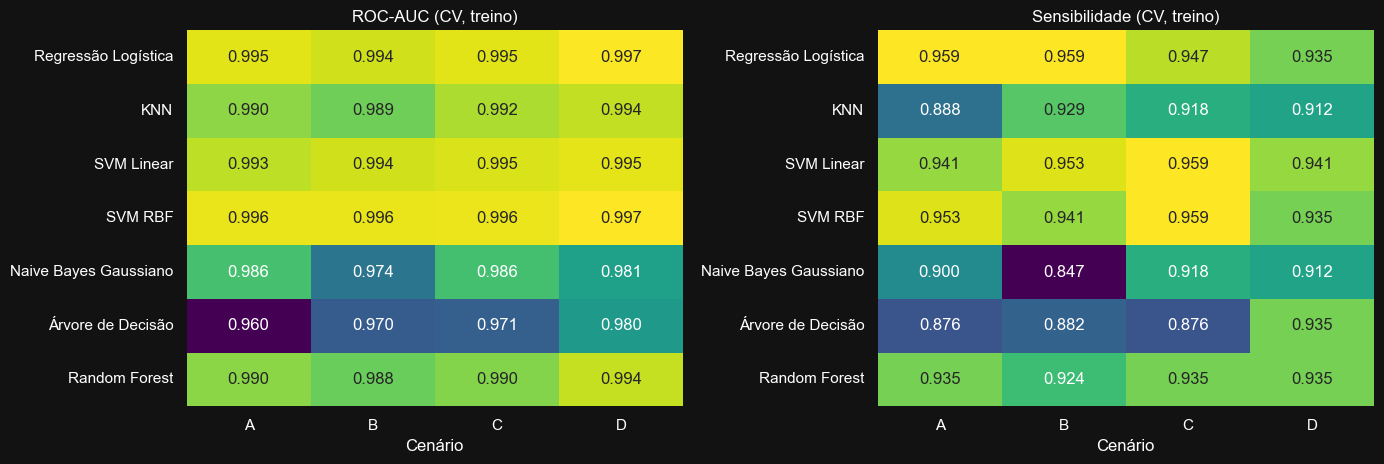

Ranking com validação cruzada repetida (10 x 3), teste t pareado com correção de Nadeau-Bengio e ajuste de Holm:


modelo,cenário,ROC-AUC,Sensibilidade,diferença_para_a_melhor,p_corrigido,p_holm,difere_da_melhor
SVM RBF,D,0.996300,0.939200,0.000000,1.000000,nan,(melhor)
Regressão Logística,D,0.995500,0.945100,0.000800,0.583500,1.000000,não
SVM RBF,B,0.995100,0.943100,0.001300,0.579900,1.000000,não
SVM RBF,A,0.994900,0.945100,0.001400,0.568600,1.000000,não
SVM Linear,C,0.994900,0.949000,0.001400,0.472800,1.000000,não
Regressão Logística,A,0.994300,0.949000,0.002000,0.481800,1.000000,não
SVM Linear,D,0.994000,0.929400,0.002300,0.232000,1.000000,não
Regressão Logística,C,0.993400,0.937300,0.003000,0.367900,1.000000,não


Combinações que diferem significativamente da melhor: 0 de 27


In [11]:
modelos = joblib.load(PASTA_MODELOS / "modelos_supervisionados.joblib")   # chave: (modelo, cenário)
cv = pd.read_csv(PASTA_RESULTADOS / "hiperparametros_e_cv.csv")
ranking = pd.read_csv(PASTA_RESULTADOS / "ranking_cv_repetida.csv")
assert len(modelos) == 28 and len(cv) == 28

MODELOS = ["Regressão Logística", "KNN", "SVM Linear", "SVM RBF", "Naive Bayes Gaussiano", "Árvore de Decisão", "Random Forest"]
CENARIOS = ["A", "B", "C", "D"]
DESC_CENARIO = {"A": "A: 30 atributos", "B": "B: PCA", "C": "C: SelectKBest", "D": "D: Top-10"}

print("Melhores hiperparâmetros (busca em 10 folds, ROC-AUC) e desempenho na validação cruzada do treino:")
tab_hp = cv[["modelo", "cenário", "melhores_hiperparametros", "ROC-AUC", "Sensibilidade", "Especificidade", "F1"]].copy()
display(tab_hp.round(3).style.hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col, titulo in zip(axes, ["ROC-AUC", "Sensibilidade"], ["ROC-AUC (CV, treino)", "Sensibilidade (CV, treino)"]):
    piv = cv.pivot(index="modelo", columns="cenário", values=col).loc[MODELOS, CENARIOS]
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False)
    ax.set_title(titulo); ax.set_ylabel(""); ax.set_xlabel("Cenário")
plt.tight_layout()
salvar_fig(fig, "09_cv_modelo_cenario")

print("Ranking com validação cruzada repetida (10 x 3), teste t pareado com correção de Nadeau-Bengio e ajuste de Holm:")
display(ranking.head(8).round(4).style.hide(axis="index"))
print("Combinações que diferem significativamente da melhor:", int((ranking["difere_da_melhor"] == "sim").sum()), "de", len(ranking) - 1)

**Como interpretar** (resultados do Vitor na validação cruzada do treino):
- Todos os modelos separam bem as classes: ROC-AUC entre 0,96 e 0,997. Regressão Logística, SVM Linear e SVM RBF ficam no topo, e a Árvore de Decisão tem os valores mais baixos.
- A melhor média é a do SVM RBF no cenário D, mas **nenhuma das outras 27 combinações é significativamente diferente dela** (a comparação estatística corrige para vários testes). Reduzir a dimensão (cenários B, C ou D) também não muda o desempenho de forma significativa.
- Ou seja, a validação cruzada não consegue dizer qual é o melhor entre os melhores. Diferenças de 1 a 3 pacientes no teste devem ser lidas com cuidado (Seção 8.3).

## 8. Avaliação no conjunto de teste

Esta é a primeira (e única) vez que usamos o teste (114 pacientes, 42 malignos). Regras combinadas antes de olhar os resultados:
1. As probabilidades dos 28 modelos são calculadas uma vez e nada é reajustado depois.
2. Nenhum modelo, cenário ou limiar é escolhido olhando o teste. A comparação principal usa o **cenário A** (30 atributos padronizados), igual para os 7 modelos. Os outros cenários aparecem nas tabelas e mapas de calor. Os modelos em destaque (SVM RBF em A e D, Regressão Logística em D e Árvore em A) são os que o Vitor recomendou olhando só a validação cruzada.
3. Por enquanto o limiar é 0,5. O ajuste fica na Seção 9, usando só o treino.
4. Com apenas 42 malignos, cada falso negativo vale cerca de 2,4 pontos de sensibilidade. Por isso mostramos também intervalos de confiança.

**Métricas:** acurácia, precisão, sensibilidade (ou recall: proporção de cânceres encontrados), especificidade (proporção de benignos acertados), F1, ROC-AUC e AP (área sob a curva Precision-Recall). A **sensibilidade** é a mais importante aqui.

In [12]:
# Dados do teste: os 30 atributos ORIGINAIS (os pipelines padronizam/transformam por conta própria)
y_te = y_test.values
y_tr = y_train.values

# Probabilidade de maligno de cada um dos 28 pipelines, calculada uma única vez
proba_teste = {chave: pipe.predict_proba(X_test)[:, 1] for chave, pipe in modelos.items()}


def metricas(y_true, prob, limiar=0.5):
    pred = (prob >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else np.nan
    prec, rec = div(tp, tp + fp), div(tp, tp + fn)
    return {"Acurácia": (tp + tn) / (tp + tn + fp + fn), "Precisão": prec, "Sensibilidade": rec,
            "Especificidade": div(tn, tn + fp), "F1": div(2 * prec * rec, prec + rec) if tp else 0.0,
            "VP": tp, "FP": fp, "FN": fn, "VN": tn}


linhas = []
for (mod, cen), prob in proba_teste.items():
    linhas.append({"modelo": mod, "cenário": cen, **metricas(y_te, prob),
                   "ROC-AUC": roc_auc_score(y_te, prob), "AP": average_precision_score(y_te, prob)})
res_teste = pd.DataFrame(linhas)
res_teste["modelo"] = pd.Categorical(res_teste["modelo"], MODELOS, ordered=True)
res_teste = res_teste.sort_values(["modelo", "cenário"]).reset_index(drop=True)
cols = ["modelo", "cenário", "Acurácia", "Precisão", "Sensibilidade", "Especificidade", "F1", "ROC-AUC", "AP", "VP", "FP", "FN", "VN"]
res_teste[cols].to_csv(PASTA_RESULTADOS / "metricas_teste.csv", index=False)

print("Cenário A (30 atributos padronizados): limiar 0,5, conjunto de teste")
tab_A = res_teste[res_teste["cenário"] == "A"][cols].drop(columns="cenário")
display(tab_A.round(3).style.hide(axis="index").background_gradient(subset=["Sensibilidade", "ROC-AUC", "F1"], cmap="viridis"))

Cenário A (30 atributos padronizados): limiar 0,5, conjunto de teste


modelo,Acurácia,Precisão,Sensibilidade,Especificidade,F1,ROC-AUC,AP,VP,FP,FN,VN
Regressão Logística,0.974000,0.976000,0.952000,0.986000,0.964000,0.996000,0.994000,40,1,2,71
KNN,0.947000,1.000000,0.857000,1.000000,0.923000,0.996000,0.994000,36,0,6,72
SVM Linear,0.956000,1.000000,0.881000,1.000000,0.937000,0.991000,0.988000,37,0,5,72
SVM RBF,0.982000,1.000000,0.952000,1.000000,0.976000,0.996000,0.995000,40,0,2,72
Naive Bayes Gaussiano,0.921000,0.923000,0.857000,0.958000,0.889000,0.989000,0.982000,36,3,6,69
Árvore de Decisão,0.939000,0.927000,0.905000,0.958000,0.916000,0.988000,0.970000,38,3,4,69
Random Forest,0.974000,1.000000,0.929000,1.000000,0.963000,0.994000,0.991000,39,0,3,72


Todos os 28 modelos no teste (ordenados por sensibilidade, depois especificidade e ROC-AUC):


,modelo,cenário,Acurácia,Precisão,Sensibilidade,Especificidade,F1,ROC-AUC,AP,VP,FP,FN,VN
0,SVM RBF,C,0.991,1.000,0.976,1.000,0.988,0.994,0.993,41,0,1,72
1,SVM RBF,A,0.982,1.000,0.952,1.000,0.976,0.996,0.995,40,0,2,72
2,SVM RBF,D,0.982,1.000,0.952,1.000,0.976,0.994,0.993,40,0,2,72
3,Regressão Logística,A,0.974,0.976,0.952,0.986,0.964,0.996,0.994,40,1,2,71
4,SVM Linear,C,0.974,0.976,0.952,0.986,0.964,0.994,0.991,40,1,2,71
5,Regressão Logística,C,0.974,0.976,0.952,0.986,0.964,0.992,0.989,40,1,2,71
6,SVM RBF,B,0.974,1.000,0.929,1.000,0.963,0.998,0.997,39,0,3,72
7,Regressão Logística,B,0.974,1.000,0.929,1.000,0.963,0.997,0.996,39,0,3,72
8,Random Forest,A,0.974,1.000,0.929,1.000,0.963,0.994,0.991,39,0,3,72
9,Random Forest,C,0.974,1.000,0.929,1.000,0.963,0.994,0.990,39,0,3,72


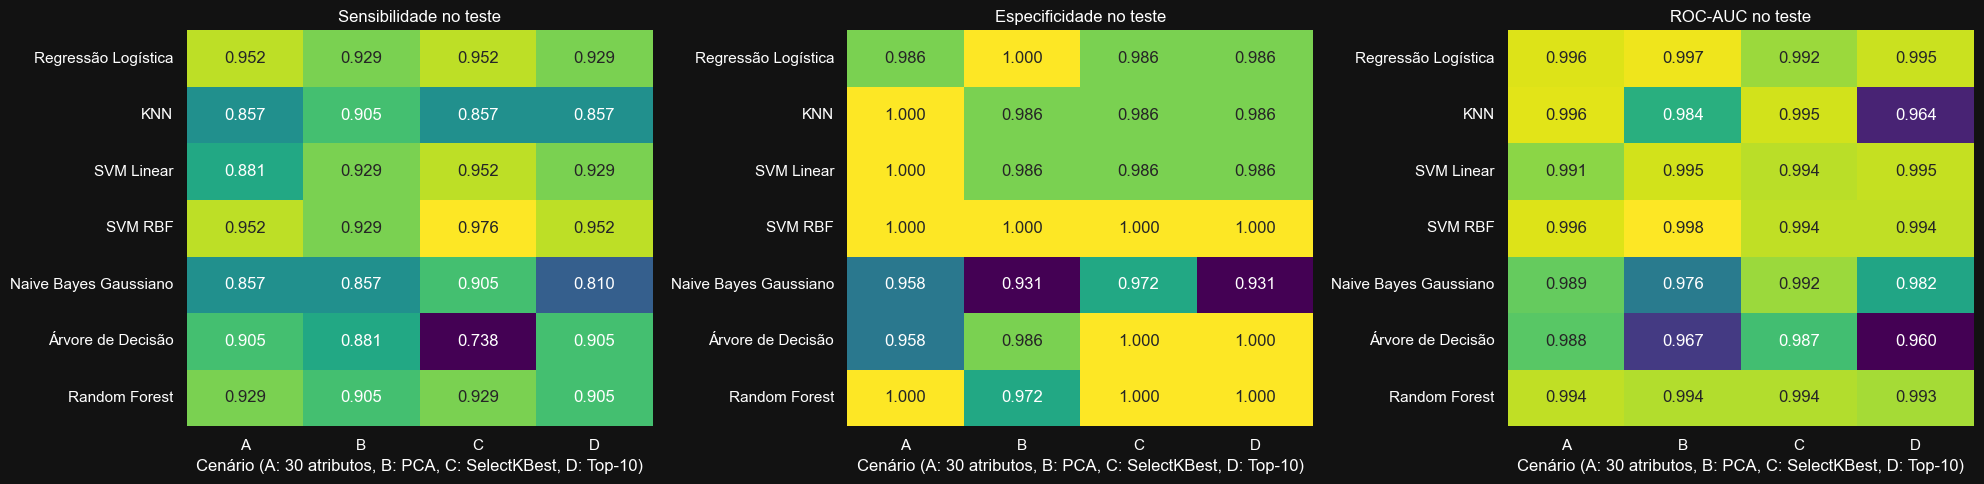

In [13]:
print("Todos os 28 modelos no teste (ordenados por sensibilidade, depois especificidade e ROC-AUC):")
display(res_teste[cols].sort_values(["Sensibilidade", "Especificidade", "ROC-AUC"], ascending=False)
        .round(3).reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, ["Sensibilidade", "Especificidade", "ROC-AUC"]):
    piv = res_teste.pivot(index="modelo", columns="cenário", values=col).loc[MODELOS, CENARIOS]
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False)
    ax.set_title(f"{col} no teste"); ax.set_ylabel(""); ax.set_xlabel("Cenário (A: 30 atributos, B: PCA, C: SelectKBest, D: Top-10)")
plt.tight_layout()
salvar_fig(fig, "10_teste_modelo_cenario")

**Como interpretar:**
- No cenário A (limiar 0,5), SVM RBF e Regressão Logística têm a maior sensibilidade: 95,2% (40 de 42 cânceres, 2 falsos negativos). O SVM RBF não tem falso positivo, e a Regressão Logística tem 1. O Random Forest erra 3 cânceres, a Árvore 4, o SVM Linear 5, e o KNN e o Naive Bayes 6 cada.
- ROC-AUC alta não garante boa sensibilidade com limiar 0,5. O KNN tem ROC-AUC de 0,996 (igual à da Regressão Logística), mas deixa passar 6 cânceres. Por isso vale ajustar o limiar (Seção 9.3).
- Nos 28 modelos, a ROC-AUC vai de 0,960 a 0,998 e a sensibilidade vai de 0,738 (Árvore no cenário C) a 0,976 (SVM RBF no cenário C). A especificidade é de pelo menos 0,93 em todos. Nenhum modelo chega a 100% de sensibilidade.

### 8.1 Curvas ROC e Precision-Recall

Colocamos as curvas dos 7 modelos (cenário A) no mesmo gráfico, com um zoom na região de alta sensibilidade, que é a que mais importa na prática. Depois repetimos para cada cenário.

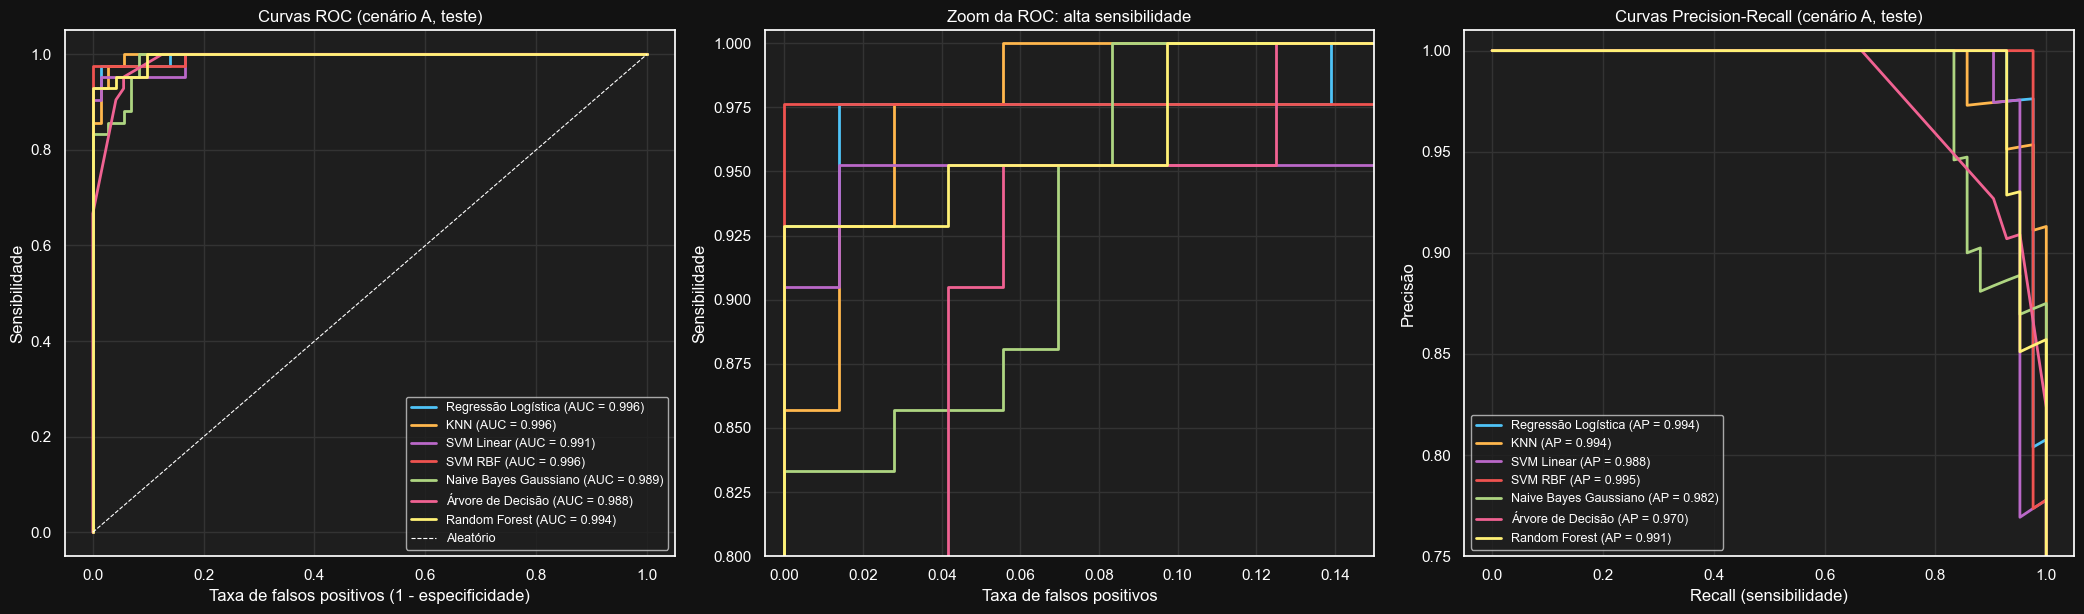

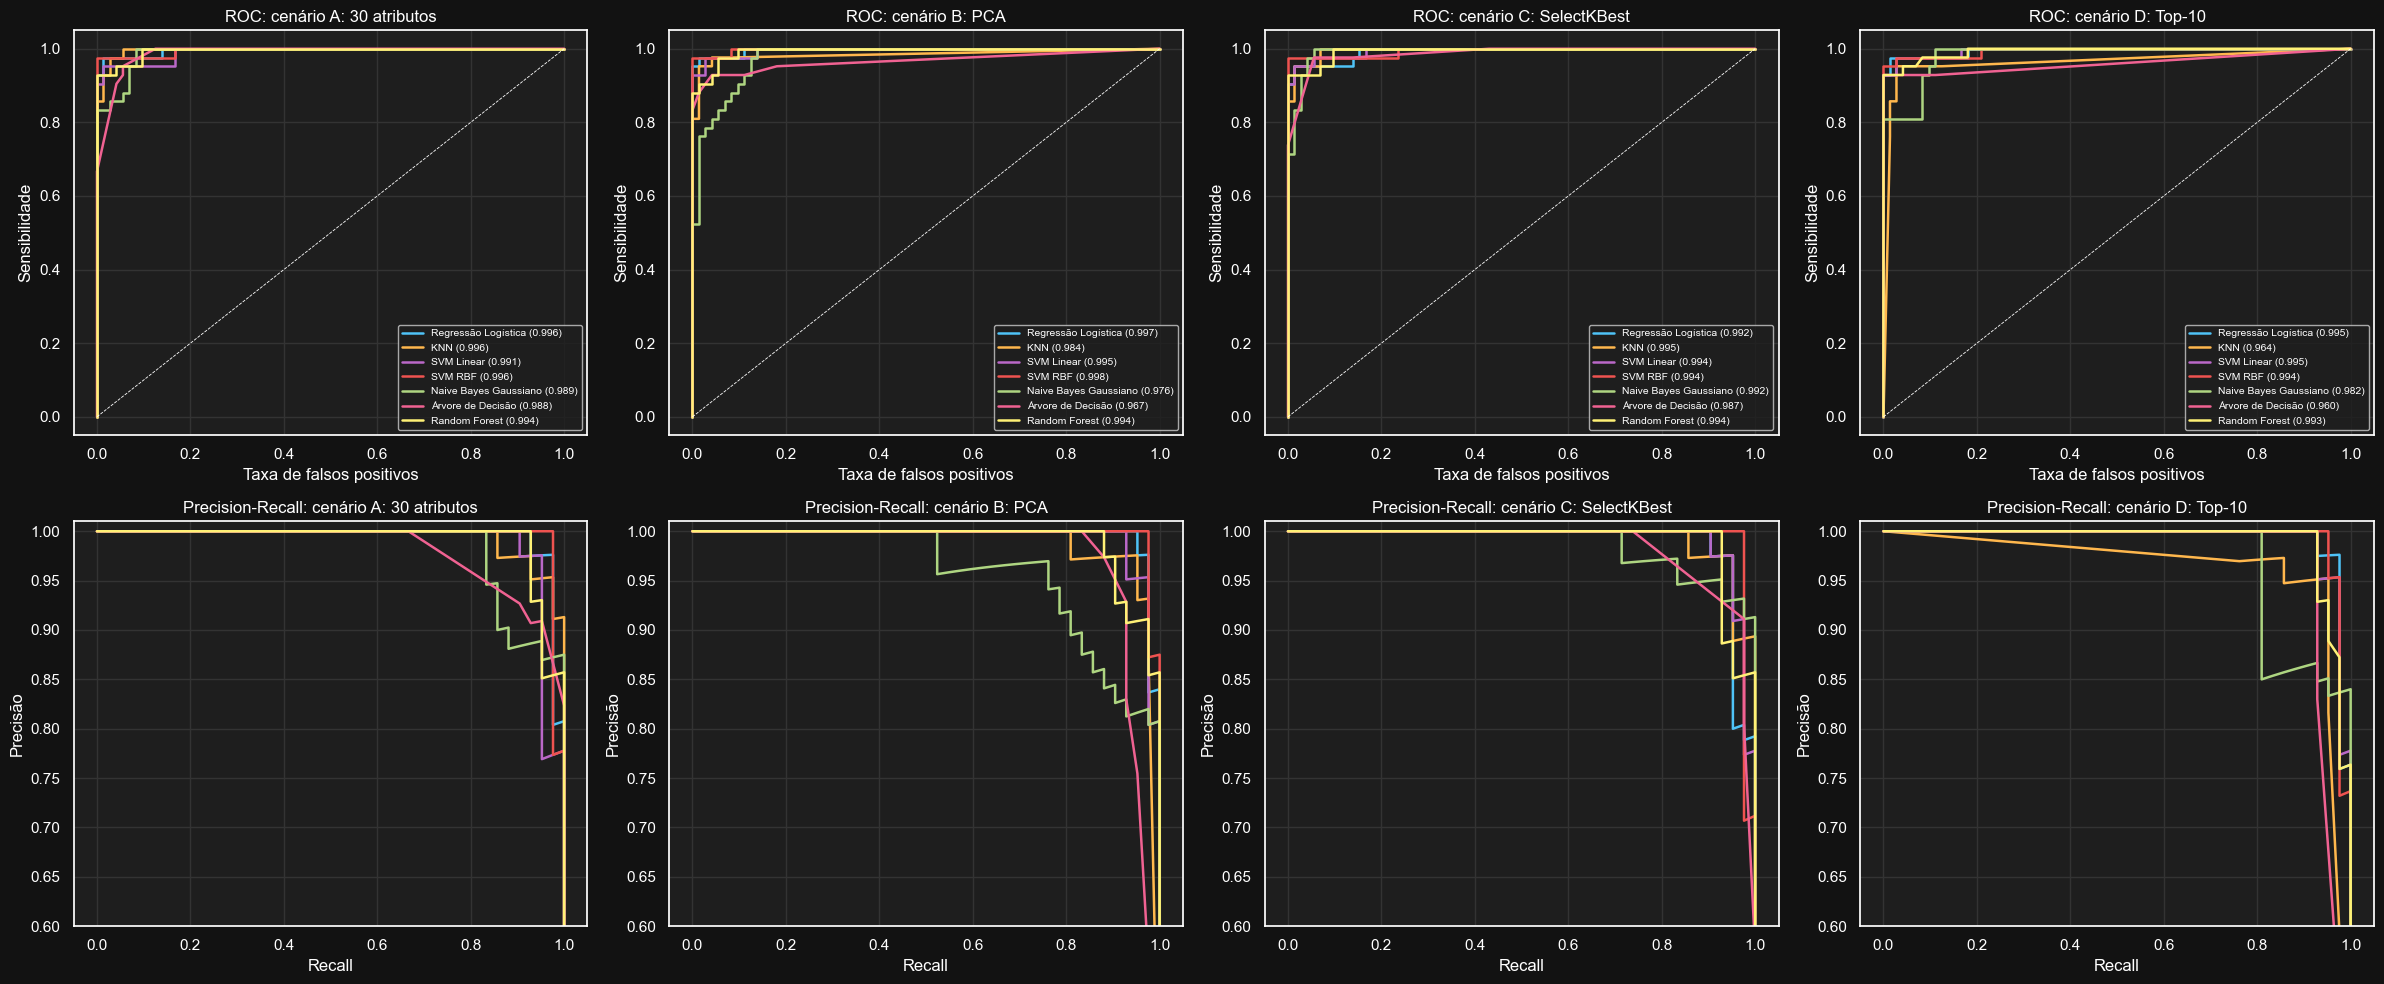

In [14]:
CORES_MOD = dict(zip(MODELOS, ["#4fc3f7", "#ffb74d", "#ba68c8", "#ef5350", "#aed581", "#f06292", "#fff176"]))

fig, axes = plt.subplots(1, 3, figsize=(21, 6.3))
for mod in MODELOS:
    prob = proba_teste[(mod, "A")]
    fpr, tpr, _ = roc_curve(y_te, prob)
    prec, rec, _ = precision_recall_curve(y_te, prob)
    auc, ap = roc_auc_score(y_te, prob), average_precision_score(y_te, prob)
    axes[0].plot(fpr, tpr, color=CORES_MOD[mod], lw=2, label=f"{mod} (AUC = {auc:.3f})")
    axes[1].plot(fpr, tpr, color=CORES_MOD[mod], lw=2, drawstyle="steps-post")
    axes[2].plot(rec, prec, color=CORES_MOD[mod], lw=2, label=f"{mod} (AP = {ap:.3f})")
axes[0].plot([0, 1], [0, 1], "w--", lw=0.8, label="Aleatório")
axes[0].set(xlabel="Taxa de falsos positivos (1 - especificidade)", ylabel="Sensibilidade", title="Curvas ROC (cenário A, teste)")
axes[0].legend(loc="lower right", fontsize=9)
axes[1].set(xlim=(-0.005, 0.15), ylim=(0.80, 1.005), xlabel="Taxa de falsos positivos", ylabel="Sensibilidade", title="Zoom da ROC: alta sensibilidade")
axes[2].set(xlabel="Recall (sensibilidade)", ylabel="Precisão", title="Curvas Precision-Recall (cenário A, teste)", ylim=(0.75, 1.01))
axes[2].legend(loc="lower left", fontsize=9)
plt.tight_layout()
salvar_fig(fig, "11_roc_pr_cenario_A")

fig, axes = plt.subplots(2, 4, figsize=(24, 10))
for j, cen in enumerate(CENARIOS):
    for mod in MODELOS:
        prob = proba_teste[(mod, cen)]
        fpr, tpr, _ = roc_curve(y_te, prob)
        prec, rec, _ = precision_recall_curve(y_te, prob)
        axes[0, j].plot(fpr, tpr, color=CORES_MOD[mod], lw=1.8, label=f"{mod} ({roc_auc_score(y_te, prob):.3f})")
        axes[1, j].plot(rec, prec, color=CORES_MOD[mod], lw=1.8)
    axes[0, j].plot([0, 1], [0, 1], "w--", lw=0.6)
    axes[0, j].set(title=f"ROC: cenário {DESC_CENARIO[cen]}", xlabel="Taxa de falsos positivos", ylabel="Sensibilidade")
    axes[0, j].legend(loc="lower right", fontsize=7.5)
    axes[1, j].set(title=f"Precision-Recall: cenário {DESC_CENARIO[cen]}", xlabel="Recall", ylabel="Precisão", ylim=(0.6, 1.01))
plt.tight_layout()
salvar_fig(fig, "12_roc_pr_por_cenario")

**Como interpretar:** no cenário A, a ROC-AUC vai de 0,988 (Árvore) a 0,996 (Regressão Logística, KNN e SVM RBF), e as curvas ficam quase juntas. No zoom, cada degrau é **um câncer** a mais ou a menos encontrado (2,4 pontos de sensibilidade), então as diferenças entre os melhores são de 1 ou 2 pacientes. Na curva Precision-Recall, Naive Bayes (AP 0,982) e Árvore (0,970) ficam abaixo dos outros (0,988 a 0,995).

Por cenário, KNN e Árvore no cenário D têm as piores ROC-AUC (0,964 e 0,960), ao contrário da validação cruzada, em que o D era o melhor cenário deles. Isso confirma o alerta do Vitor: a lista fixa do Top-10 dá uma vantagem artificial a esses dois modelos na validação cruzada.

### 8.2 Matrizes de confusão

Matriz de cada modelo (cenário A, limiar 0,5). Cada quadrado mostra a contagem e a porcentagem da linha. A linha de baixo (com contorno vermelho) é a dos cânceres reais: o quadrado "Maligno previsto como Benigno" é o falso negativo.

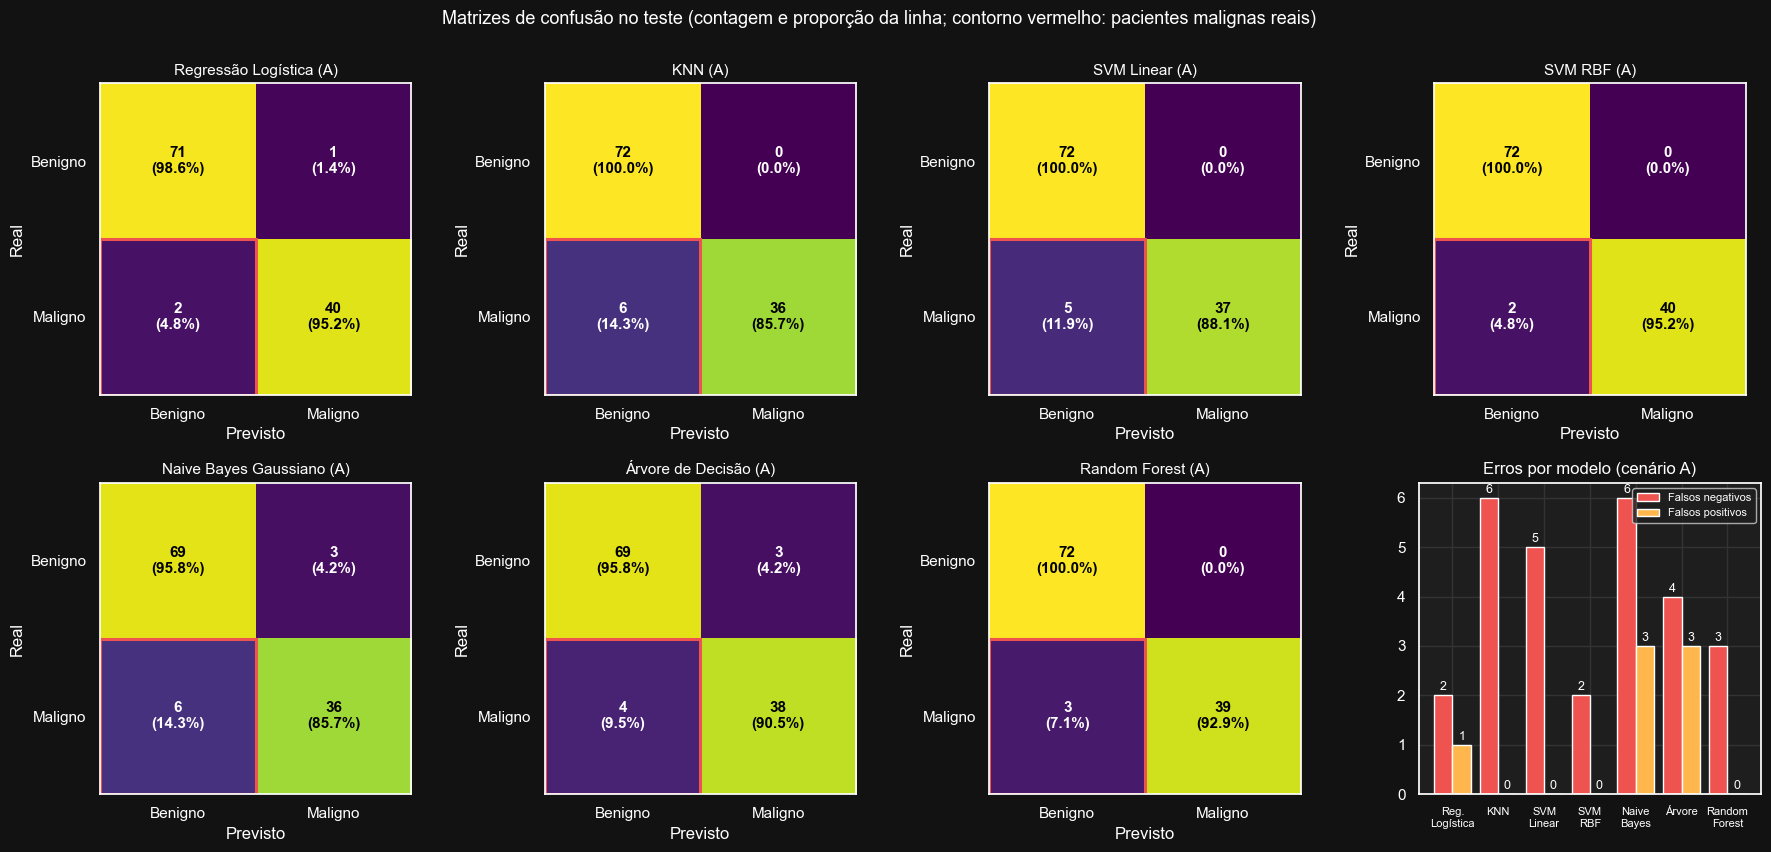

In [15]:
def plot_cm(ax, y_true, prob, limiar, titulo, fonte=11):
    pred = (prob >= limiar).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap="viridis", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({norm[i, j]:.1%})", ha="center", va="center", fontsize=fonte,
                    color="white" if norm[i, j] < 0.6 else "black", fontweight="bold")
    ax.set_xticks([0, 1], ["Benigno", "Maligno"]); ax.set_yticks([0, 1], ["Benigno", "Maligno"])
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.set_title(titulo, fontsize=11)
    ax.grid(False)
    ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, ec=COR_M, lw=2.2))   # linha dos malignos reais


fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, mod in zip(axes.ravel(), MODELOS):
    plot_cm(ax, y_te, proba_teste[(mod, "A")], 0.5, f"{mod} (A)")
ax = axes.ravel()[-1]
r_A = res_teste[res_teste["cenário"] == "A"].set_index("modelo").loc[MODELOS]
x = np.arange(len(MODELOS))
ax.bar(x - 0.2, r_A["FN"], 0.4, color=COR_M, label="Falsos negativos")
ax.bar(x + 0.2, r_A["FP"], 0.4, color="#ffb74d", label="Falsos positivos")
CURTO = {"Regressão Logística": "Reg.\nLogística", "KNN": "KNN", "SVM Linear": "SVM\nLinear", "SVM RBF": "SVM\nRBF",
         "Naive Bayes Gaussiano": "Naive\nBayes", "Árvore de Decisão": "Árvore", "Random Forest": "Random\nForest"}
ax.set_xticks(x, [CURTO[m] for m in MODELOS], fontsize=8)
ax.set_title("Erros por modelo (cenário A)"); ax.legend(fontsize=8)
for xi, (fn_, fp_) in enumerate(zip(r_A["FN"], r_A["FP"])):
    ax.text(xi - 0.2, fn_ + 0.1, int(fn_), ha="center", fontsize=9); ax.text(xi + 0.2, fp_ + 0.1, int(fp_), ha="center", fontsize=9)
plt.suptitle("Matrizes de confusão no teste (contagem e proporção da linha; contorno vermelho: pacientes malignas reais)", y=1.0, fontsize=13)
plt.tight_layout()
salvar_fig(fig, "13_matrizes_confusao_A")

**Como interpretar:**
- **SVM RBF** e **Random Forest** não têm falso positivo e erram 2 e 3 cânceres.
- **Regressão Logística** erra 2 cânceres e 1 benigno.
- **KNN** e **SVM Linear** acertam todos os benignos, mas deixam passar 6 e 5 cânceres. Eles acertam mais a classe maior (benigna) do que a menor, que é a mais importante.
- **Naive Bayes** e **Árvore** têm 3 falsos positivos cada, e também 6 e 4 falsos negativos.
- Nos 7 modelos há mais falsos negativos do que falsos positivos. Com limiar 0,5, eles erram mais no lado que o médico quer evitar.

### 8.3 Incerteza das estimativas (bootstrap)

Com 114 pacientes, as diferenças entre modelos são de poucos casos. Por isso refizemos o teste 2.000 vezes com amostras sorteadas com reposição (bootstrap, sorteando dentro de cada classe) e calculamos o intervalo de 95% da sensibilidade, da especificidade e da ROC-AUC.

modelo,cenário,Sensibilidade,Especificidade,ROC-AUC
Regressão Logística,A,0.952 [0.881; 1.000],0.986 [0.958; 1.000],0.996 [0.987; 1.000]
KNN,A,0.857 [0.738; 0.952],1.000 [1.000; 1.000],0.996 [0.989; 1.000]
SVM Linear,A,0.881 [0.762; 0.976],1.000 [1.000; 1.000],0.991 [0.978; 1.000]
SVM RBF,A,0.952 [0.881; 1.000],1.000 [1.000; 1.000],0.996 [0.985; 1.000]
Naive Bayes Gaussiano,A,0.857 [0.738; 0.952],0.958 [0.903; 1.000],0.989 [0.975; 0.998]
Árvore de Decisão,A,0.905 [0.810; 0.976],0.958 [0.903; 1.000],0.988 [0.974; 0.998]
Random Forest,A,0.929 [0.833; 1.000],1.000 [1.000; 1.000],0.994 [0.984; 1.000]
SVM RBF,D,0.952 [0.881; 1.000],1.000 [1.000; 1.000],0.994 [0.981; 1.000]
Regressão Logística,D,0.929 [0.833; 1.000],0.986 [0.958; 1.000],0.995 [0.983; 1.000]


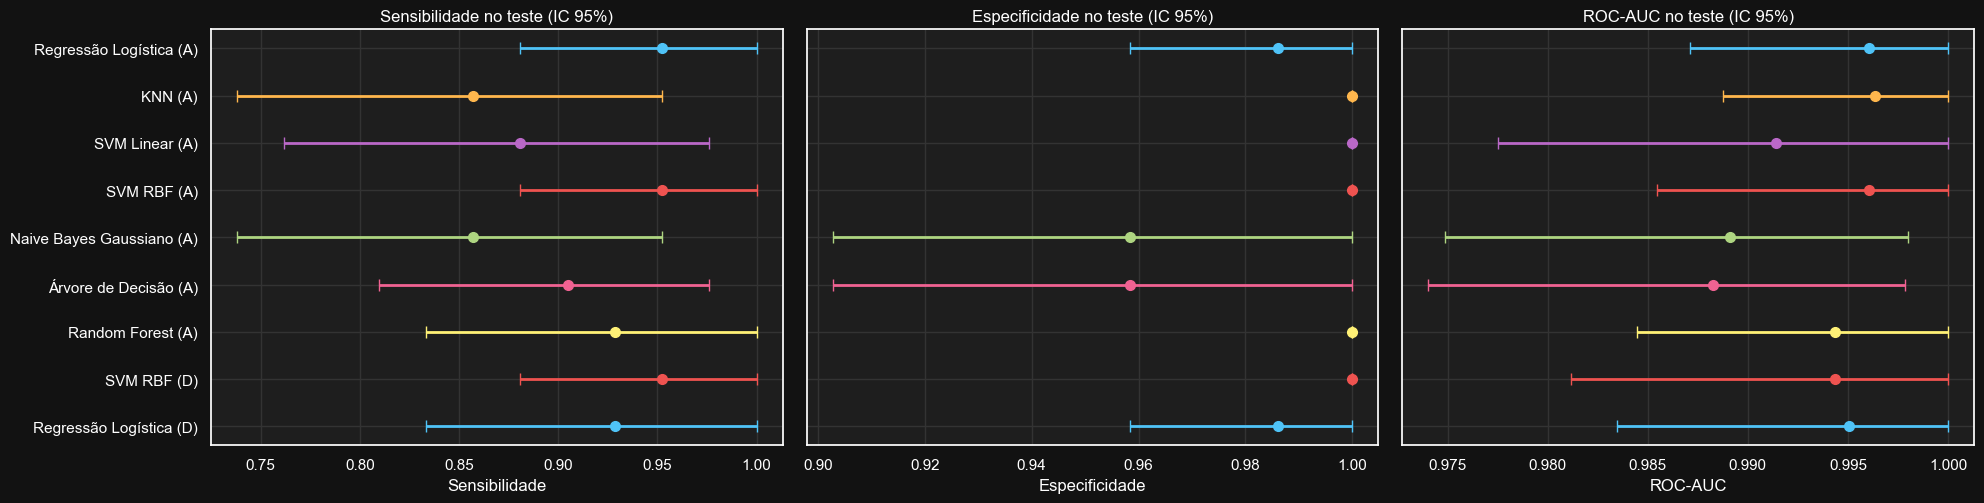

In [16]:
rng = np.random.default_rng(RANDOM_STATE)
pos, neg = np.where(y_te == 1)[0], np.where(y_te == 0)[0]
N_BOOT = 2000
amostras = [np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))] for _ in range(N_BOOT)]


def bootstrap_ic(prob, limiar=0.5):
    pred = (prob >= limiar)
    sens = np.array([pred[a[:len(pos)]].mean() for a in amostras])
    esp = np.array([(~pred[a[len(pos):]]).mean() for a in amostras])
    auc = np.array([roc_auc_score(y_te[a], prob[a]) for a in amostras])
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in
            {"Sensibilidade": sens, "Especificidade": esp, "ROC-AUC": auc}.items()}


CHAVES_IC = [(m, "A") for m in MODELOS] + [("SVM RBF", "D"), ("Regressão Logística", "D")]
ic = {k: bootstrap_ic(proba_teste[k]) for k in CHAVES_IC}

linhas = []
for k in CHAVES_IC:
    base = res_teste[(res_teste["modelo"] == k[0]) & (res_teste["cenário"] == k[1])].iloc[0]
    linhas.append({"modelo": k[0], "cenário": k[1],
                   **{m: f"{base[m]:.3f} [{ic[k][m][0]:.3f}; {ic[k][m][1]:.3f}]" for m in ["Sensibilidade", "Especificidade", "ROC-AUC"]}})
tab_ic = pd.DataFrame(linhas)
tab_ic.to_csv(PASTA_RESULTADOS / "metricas_teste_ic95.csv", index=False)
display(tab_ic.style.hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.2), sharey=True)
rotulo_k = [f"{m} ({c})" for m, c in CHAVES_IC]
for ax, met in zip(axes, ["Sensibilidade", "Especificidade", "ROC-AUC"]):
    for i, k in enumerate(CHAVES_IC):
        base = res_teste[(res_teste["modelo"] == k[0]) & (res_teste["cenário"] == k[1])].iloc[0][met]
        lo, hi = ic[k][met]
        ax.errorbar(base, i, xerr=[[base - lo], [hi - base]], fmt="o", color=CORES_MOD[k[0]], capsize=4, lw=2, ms=7)
    ax.set_yticks(range(len(CHAVES_IC)), rotulo_k); ax.invert_yaxis()
    ax.set_title(f"{met} no teste (IC 95%)"); ax.set_xlabel(met)
plt.tight_layout()
salvar_fig(fig, "14_intervalos_confianca")

**Como interpretar:** os intervalos são largos porque só há 42 malignos. A sensibilidade do SVM RBF (A) é 0,952, com intervalo [0,881; 1,000], e a do KNN é 0,857, com [0,738; 0,952]. Os intervalos se sobrepõem bastante, e o limite inferior da ROC-AUC é de pelo menos 0,974 em todos os modelos. Ou seja, **o teste não permite dizer que um modelo é melhor que outro**. Só dá para dizer que todos os principais têm ROC-AUC de 0,99 ou mais. Isso combina com a comparação da validação cruzada. Os intervalos mostram só a variação da amostra de teste.

### 8.4 Tabela consolidada

Juntamos validação cruzada e teste. Para cada modelo, usamos o cenário com maior ROC-AUC na validação cruzada (escolha feita sem olhar o teste). Também mostramos o efeito de reduzir os atributos: a diferença entre cada cenário reduzido (B, C e D) e o A.

modelo,cenário (melhor na CV),ROC-AUC (CV),ROC-AUC (teste),Sensibilidade (teste),Especificidade (teste),F1 (teste),FN,FP,"ROC-AUC (A, teste)","Sensibilidade (A, teste)"
Regressão Logística,D,0.997000,0.995000,0.929000,0.986000,0.951000,3,1,0.996000,0.952000
KNN,D,0.994000,0.964000,0.857000,0.986000,0.911000,6,1,0.996000,0.857000
SVM Linear,D,0.995000,0.995000,0.929000,0.986000,0.951000,3,1,0.991000,0.881000
SVM RBF,D,0.997000,0.994000,0.952000,1.000000,0.976000,2,0,0.996000,0.952000
Naive Bayes Gaussiano,A,0.986000,0.989000,0.857000,0.958000,0.889000,6,3,0.989000,0.857000
Árvore de Decisão,D,0.980000,0.960000,0.905000,1.000000,0.950000,4,0,0.988000,0.905000
Random Forest,D,0.994000,0.993000,0.905000,1.000000,0.950000,4,0,0.994000,0.929000


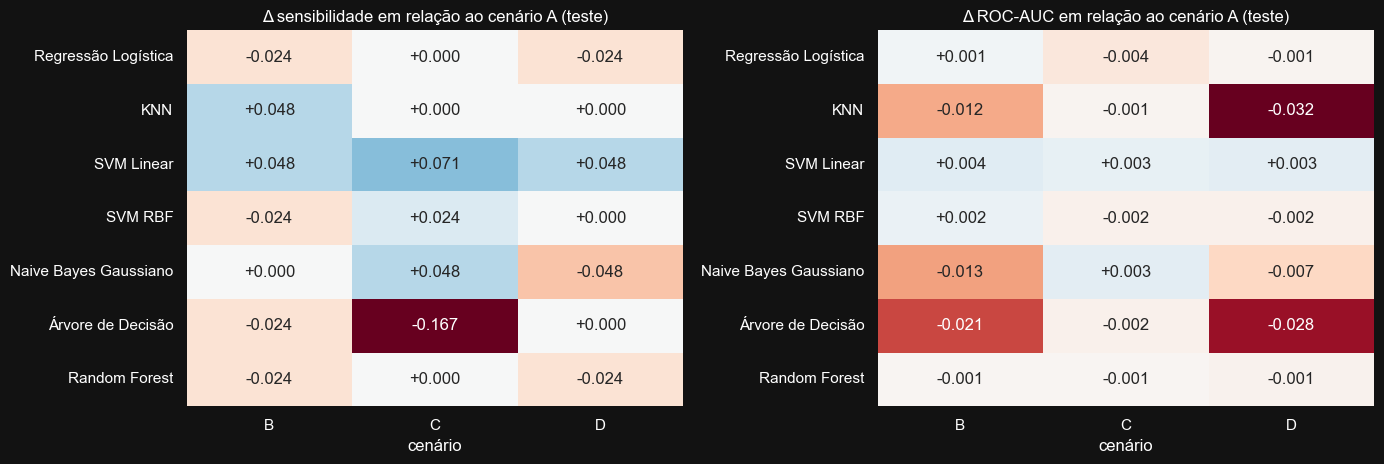

In [17]:
melhor_cv = cv.loc[cv.groupby("modelo")["ROC-AUC"].idxmax()].set_index("modelo").loc[MODELOS]
final = []
for mod in MODELOS:
    cen = melhor_cv.loc[mod, "cenário"]
    t = res_teste[(res_teste["modelo"] == mod) & (res_teste["cenário"] == cen)].iloc[0]
    tA = res_teste[(res_teste["modelo"] == mod) & (res_teste["cenário"] == "A")].iloc[0]
    final.append({"modelo": mod, "cenário (melhor na CV)": cen, "ROC-AUC (CV)": melhor_cv.loc[mod, "ROC-AUC"],
                  "ROC-AUC (teste)": t["ROC-AUC"], "Sensibilidade (teste)": t["Sensibilidade"],
                  "Especificidade (teste)": t["Especificidade"], "F1 (teste)": t["F1"], "FN": t["FN"], "FP": t["FP"],
                  "ROC-AUC (A, teste)": tA["ROC-AUC"], "Sensibilidade (A, teste)": tA["Sensibilidade"]})
tab_final = pd.DataFrame(final)
tab_final.to_csv(PASTA_RESULTADOS / "tabela_final_modelos.csv", index=False)
display(tab_final.round(3).style.hide(axis="index"))

# Efeito de reduzir a dimensão (diferença para o cenário A, no teste)
delta = []
for mod in MODELOS:
    a = res_teste[(res_teste["modelo"] == mod) & (res_teste["cenário"] == "A")].iloc[0]
    for cen in ["B", "C", "D"]:
        r_ = res_teste[(res_teste["modelo"] == mod) & (res_teste["cenário"] == cen)].iloc[0]
        delta.append({"modelo": mod, "cenário": cen, "Δ sensibilidade": r_["Sensibilidade"] - a["Sensibilidade"],
                      "Δ ROC-AUC": r_["ROC-AUC"] - a["ROC-AUC"]})
delta = pd.DataFrame(delta)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col in zip(axes, ["Δ sensibilidade", "Δ ROC-AUC"]):
    sns.heatmap(delta.pivot(index="modelo", columns="cenário", values=col).loc[MODELOS], annot=True, fmt="+.3f",
                cmap="RdBu", center=0, ax=ax, cbar=False)
    ax.set_title(f"{col} em relação ao cenário A (teste)"); ax.set_ylabel("")
plt.tight_layout()
salvar_fig(fig, "15_efeito_reducao_dimensao")

**Como interpretar:**
- Regressão Logística e SVM RBF no cenário D repetem no teste o que a validação cruzada mostrou (ROC-AUC de 0,995 e 0,994). O SVM RBF tem a melhor sensibilidade (95,2%) e o melhor F1 (0,976), sem falso positivo.
- KNN e Árvore pioram em relação à validação cruzada (KNN: de 0,994 para 0,964; Árvore: de 0,980 para 0,960). É o efeito da lista fixa do Top-10.
- Para Regressão Logística, SVMs e Random Forest, a ROC-AUC muda no máximo 0,005 entre o cenário A e os reduzidos, e a sensibilidade muda no máximo 3 pacientes. Então **10 atributos (cenário D) bastam** para manter o desempenho dos melhores modelos. As exceções são a Árvore (no cenário C ela perde 7 cânceres detectados) e o KNN no D. O PCA não ajuda nem atrapalha de forma clara.
- Recomendação (definida antes do teste): **SVM RBF**, com 30 atributos (A) ou com o Top-10 (D), e **Regressão Logística no D** como opção fácil de explicar. Pelos intervalos da Seção 8.3, não dá para separar um do outro.

## 9. Discussão

### 9.1 Por que o falso negativo é o pior erro

- **Falso negativo:** a paciente tem câncer e recebe a notícia de que está tudo bem. O diagnóstico e o tratamento atrasam, e a doença pode avançar.
- **Falso positivo:** a paciente não tem câncer, mas é chamada para mais exames ou biópsia. Causa susto e custo, mas o erro é descoberto depois.

Por isso a **sensibilidade** é a métrica principal, e a acurácia sozinha engana (com 63% de benignos, um modelo ruim já parece bom). Em vez de usar sempre o limiar 0,5, é melhor escolher o limiar pensando no custo de cada erro. Quanto um falso negativo pesa a mais que um falso positivo depende do contexto clínico. Na Seção 9.4 testamos razões de 1 a 50.

### 9.2 Quem são os falsos negativos?

Para cada câncer do teste, contamos em quantos dos 28 modelos ele é classificado como benigno (limiar 0,5). Se os mesmos casos aparecem em muitos modelos, o problema está nos dados e não no modelo.

16 das 42 pacientes malignas do teste são perdidas por pelo menos 1 dos 28 modelos.
Perdidas por mais da metade dos modelos (> 14 de 28): 2


,id da paciente,modelos que erram (de 28)
73,859983,28
205,879523,18
385,90291,14
99,862548,13
86,86135501,11
100,862717,9
39,855138,5
190,874858,5
5,843786,3
277,8911670,2


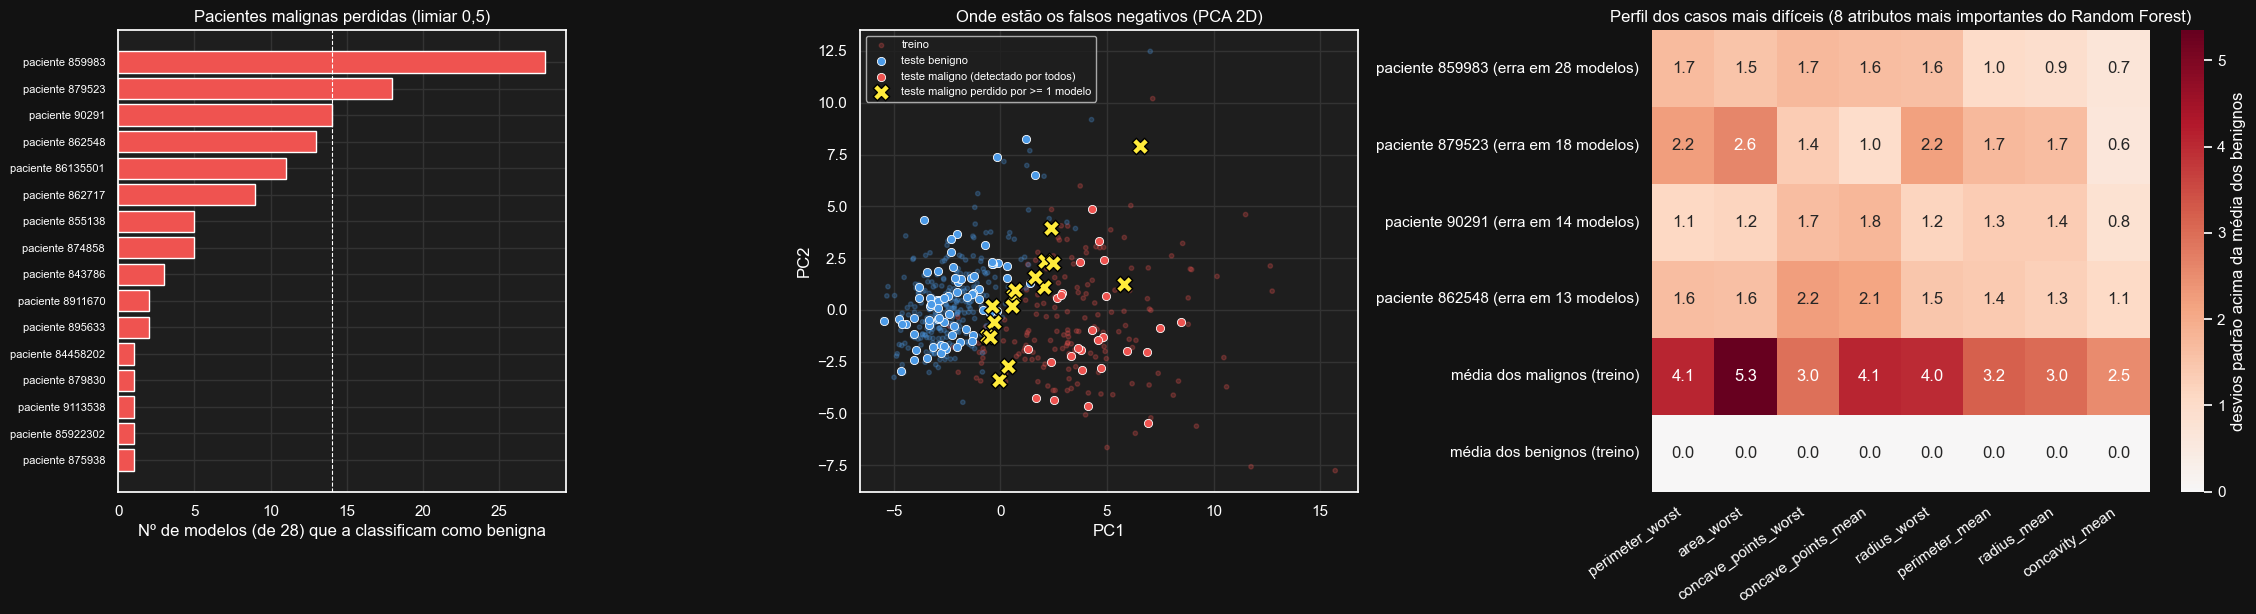

In [18]:
perdeu = pd.DataFrame({k: (p < 0.5) for k, p in proba_teste.items()})      # prevê benigno
perdeu.index = X_test.index
mal_idx = X_test.index[y_te == 1]
n_perdem = perdeu.loc[mal_idx].sum(axis=1).sort_values(ascending=False)
fn_casos = n_perdem[n_perdem > 0]
print(f"{len(fn_casos)} das {len(mal_idx)} pacientes malignas do teste são perdidas por pelo menos 1 dos 28 modelos.")
print(f"Perdidas por mais da metade dos modelos (> 14 de 28): {(fn_casos > 14).sum()}")
tabela_fn = pd.DataFrame({"id da paciente": df.loc[fn_casos.index, "id"].values, "modelos que erram (de 28)": fn_casos.values},
                         index=fn_casos.index)
display(tabela_fn.head(10))

# Perfil dos casos mais difíceis: z-score em relação ao treino BENIGNO e ao treino MALIGNO
top_fn = fn_casos.index[:4]
imp_rf = pd.Series(modelos[("Random Forest", "A")].named_steps["modelo"].feature_importances_, index=X.columns).sort_values(ascending=False)
feat_chave = list(imp_rf.head(8).index)
mu_b, sd_b = X_train[y_train == 0][feat_chave].mean(), X_train[y_train == 0][feat_chave].std()
perfil = pd.DataFrame({f"paciente {df.loc[i, 'id']} (erra em {n_perdem[i]} modelos)": (X_test.loc[i, feat_chave] - mu_b) / sd_b for i in top_fn}).T
perfil.loc["média dos malignos (treino)"] = (X_train[y_train == 1][feat_chave].mean() - mu_b) / sd_b
perfil.loc["média dos benignos (treino)"] = 0.0

fig, axes = plt.subplots(1, 3, figsize=(23, 6.3), gridspec_kw={"width_ratios": [0.9, 1, 1.25]})
axes[0].barh(range(len(fn_casos)), fn_casos.values[::-1], color=COR_M)
axes[0].set_yticks(range(len(fn_casos)), [f"paciente {df.loc[i, 'id']}" for i in fn_casos.index[::-1]], fontsize=8)
axes[0].axvline(14, color="white", ls="--", lw=0.8); axes[0].set_xlabel("Nº de modelos (de 28) que a classificam como benigna")
axes[0].set_title("Pacientes malignas perdidas (limiar 0,5)")

Zte = pca_2d.transform(pd.DataFrame(escala_treino.transform(X_test), columns=X.columns, index=X_test.index))
Zte = pd.DataFrame(Zte, index=X_test.index, columns=["PC1", "PC2"])
axes[1].scatter(Z2[:, 0], Z2[:, 1], c=np.where(ytr == 1, COR_M, COR_B), s=10, alpha=0.25, label="treino")
b_te = Zte.loc[X_test.index[y_te == 0]]; m_te = Zte.loc[[i for i in mal_idx if i not in fn_casos.index]]
axes[1].scatter(b_te["PC1"], b_te["PC2"], c=COR_B, s=35, edgecolor="white", lw=0.6, label="teste benigno")
axes[1].scatter(m_te["PC1"], m_te["PC2"], c=COR_M, s=35, edgecolor="white", lw=0.6, label="teste maligno (detectado por todos)")
f_te = Zte.loc[fn_casos.index]
axes[1].scatter(f_te["PC1"], f_te["PC2"], c="#ffeb3b", marker="X", s=140, edgecolor="black", lw=1, label="teste maligno perdido por >= 1 modelo")
axes[1].set(xlabel="PC1", ylabel="PC2", title="Onde estão os falsos negativos (PCA 2D)"); axes[1].legend(fontsize=8)

sns.heatmap(perfil, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=axes[2], cbar_kws={"label": "desvios padrão acima da média dos benignos"})
axes[2].set_title("Perfil dos casos mais difíceis (8 atributos mais importantes do Random Forest)")
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=35, ha="right")
plt.tight_layout()
salvar_fig(fig, "16_falsos_negativos")

**Como interpretar:**
- **16 dos 42 cânceres** do teste são perdidos por pelo menos um dos 28 modelos, mas metade deles por 3 modelos ou menos. Dois são perdidos por mais da metade dos modelos, e a paciente de ID **859983 é perdida por todos os 28** (a de ID 879523, por 18).
- Esses casos **parecem benignos** nas medidas: nos 8 atributos mais importantes, ficam em geral de 1 a 2 desvios padrão acima da média dos benignos (no máximo 2,6), enquanto a média dos malignos fica de 2,5 a 5,3. No PCA, aparecem na região entre as duas classes.
- Ou seja, o erro vem dos dados, e trocar de modelo não resolve. Nenhum modelo baseado só nesses 30 atributos deve decidir sozinho. Casos que não batem com o exame clínico ou de imagem precisam ser revistos pelo especialista.

### 9.3 Ajuste do limiar de decisão

O limiar 0,5 é só uma convenção. Baixando o limiar, mais pacientes são classificadas como malignas: perdemos menos cânceres, mas aparecem mais falsos positivos. Para não usar o teste na escolha:
1. Calculamos probabilidades "fora da amostra" no treino (`cross_val_predict`, 10 partes): cada paciente é prevista por um modelo que não a viu.
2. Escolhemos o limiar nessas previsões com a regra **"o maior limiar em que a sensibilidade ainda é de pelo menos 98%"**. Comparamos com duas regras conhecidas: **Youden** (sensibilidade + especificidade - 1) e **F2** (dá mais peso à sensibilidade).
3. Aplicamos o limiar escolhido no teste, uma vez.

Modelos em destaque: SVM RBF (A e D), Regressão Logística (D) e Árvore de Decisão (A).

In [19]:
DESTAQUE = [("SVM RBF", "A"), ("SVM RBF", "D"), ("Regressão Logística", "D"), ("Árvore de Decisão", "A")]
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

# 1) Probabilidades fora da amostra no TREINO (o teste não entra aqui)
oof = {k: cross_val_predict(clone(modelos[k]), X_train, y_train, cv=cv10, method="predict_proba")[:, 1] for k in DESTAQUE}


def limiar_recall(p_oof, alvo=0.98):
    cand = np.unique(p_oof)
    ok = [t for t in cand if (p_oof[y_tr == 1] >= t).mean() >= alvo]
    return float(max(ok))


def limiar_youden(p_oof):
    fpr, tpr, thr = roc_curve(y_tr, p_oof)
    return float(thr[np.argmax(tpr - fpr)])


def limiar_f2(p_oof):
    prec, rec, thr = precision_recall_curve(y_tr, p_oof)
    f2 = 5 * prec[:-1] * rec[:-1] / np.maximum(4 * prec[:-1] + rec[:-1], 1e-12)
    return float(thr[np.argmax(f2)])


REGRAS = {"padrão (0,5)": lambda p: 0.5, "Youden": limiar_youden, "melhor F2": limiar_f2, "recall >= 98% (escolhida)": limiar_recall}
linhas = []
for k in DESTAQUE:
    for nome_regra, regra in REGRAS.items():
        t = regra(oof[k])
        m_oof, m_te = metricas(y_tr, oof[k], t), metricas(y_te, proba_teste[k], t)
        linhas.append({"modelo": k[0], "cenário": k[1], "regra": nome_regra, "limiar": t,
                       "Sens. (treino, fora da amostra)": m_oof["Sensibilidade"], "Espec. (treino, fora da amostra)": m_oof["Especificidade"],
                       "Sens. (teste)": m_te["Sensibilidade"], "Espec. (teste)": m_te["Especificidade"],
                       "FN (teste)": m_te["FN"], "FP (teste)": m_te["FP"]})
tab_lim = pd.DataFrame(linhas)
tab_lim.to_csv(PASTA_RESULTADOS / "limiares.csv", index=False)
display(tab_lim.round(3).style.hide(axis="index"))
LIM_ESC = {k: float(tab_lim[(tab_lim["modelo"] == k[0]) & (tab_lim["cenário"] == k[1]) & (tab_lim["regra"] == "recall >= 98% (escolhida)")]["limiar"].iloc[0]) for k in DESTAQUE}

# Quais pacientes continuam como falso negativo depois do ajuste?
for k in DESTAQUE:
    resto = X_test.index[(y_te == 1) & (proba_teste[k] < LIM_ESC[k])]
    print(f"{k[0]} ({k[1]}), limiar {LIM_ESC[k]:.3f}: falsos negativos restantes -> ids {list(df.loc[resto, 'id'])}")

modelo,cenário,regra,limiar,"Sens. (treino, fora da amostra)","Espec. (treino, fora da amostra)",Sens. (teste),Espec. (teste),FN (teste),FP (teste)
SVM RBF,A,"padrão (0,5)",0.500000,0.953000,0.979000,0.952000,1.000000,2,0
SVM RBF,A,Youden,0.340000,0.976000,0.972000,0.976000,1.000000,1,0
SVM RBF,A,melhor F2,0.177000,0.988000,0.947000,0.976000,0.972000,1,2
SVM RBF,A,recall >= 98% (escolhida),0.181000,0.982000,0.947000,0.976000,0.972000,1,2
SVM RBF,D,"padrão (0,5)",0.500000,0.935000,0.989000,0.952000,1.000000,2,0
SVM RBF,D,Youden,0.205000,0.988000,0.965000,0.976000,0.958000,1,3
SVM RBF,D,melhor F2,0.205000,0.988000,0.965000,0.976000,0.958000,1,3
SVM RBF,D,recall >= 98% (escolhida),0.215000,0.982000,0.965000,0.976000,0.958000,1,3
Regressão Logística,D,"padrão (0,5)",0.500000,0.935000,0.982000,0.929000,0.986000,3,1
Regressão Logística,D,Youden,0.222000,0.988000,0.965000,0.976000,0.972000,1,2


SVM RBF (A), limiar 0.181: falsos negativos restantes -> ids [859983]
SVM RBF (D), limiar 0.215: falsos negativos restantes -> ids [859983]
Regressão Logística (D), limiar 0.238: falsos negativos restantes -> ids [859983]
Árvore de Decisão (A), limiar 0.008: falsos negativos restantes -> ids []


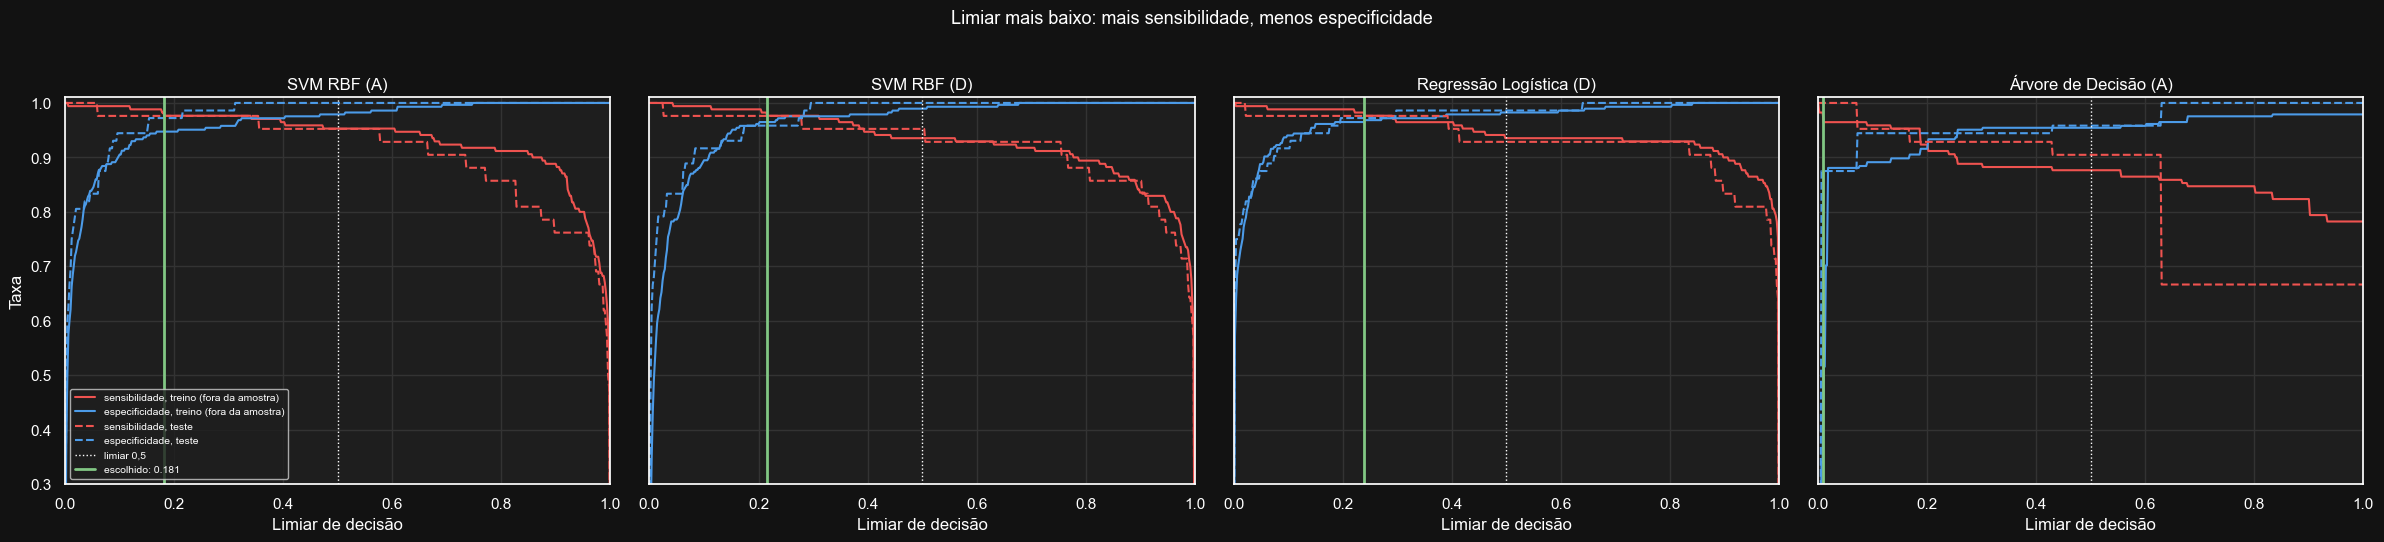

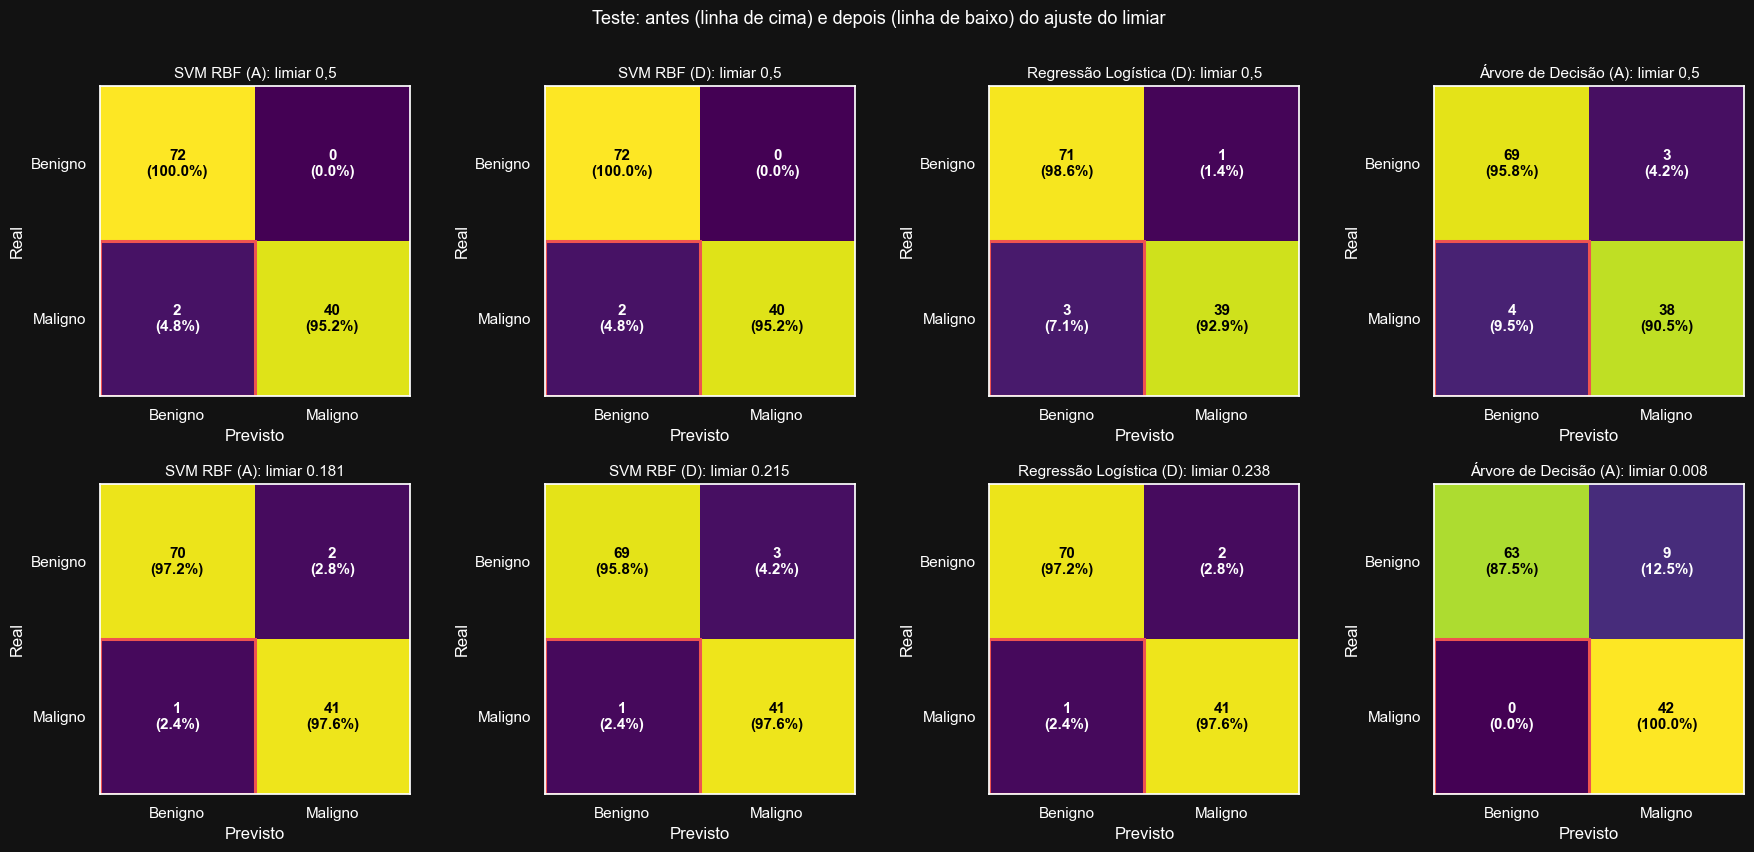

In [20]:
# Compromisso sensibilidade x especificidade em função do limiar (fora da amostra no treino x teste)
grade = np.linspace(0.0, 1.0, 501)
fig, axes = plt.subplots(1, 4, figsize=(24, 5.3), sharey=True)
for ax, k in zip(axes, DESTAQUE):
    for nome, p, yy, ls in [("treino (fora da amostra)", oof[k], y_tr, "-"), ("teste", proba_teste[k], y_te, "--")]:
        sens = [(p[yy == 1] >= t).mean() for t in grade]
        esp = [(p[yy == 0] < t).mean() for t in grade]
        ax.plot(grade, sens, ls, color=COR_M, label=f"sensibilidade, {nome}")
        ax.plot(grade, esp, ls, color=COR_B, label=f"especificidade, {nome}")
    ax.axvline(0.5, color="white", ls=":", lw=1, label="limiar 0,5")
    ax.axvline(LIM_ESC[k], color="#81c784", lw=2, label=f"escolhido: {LIM_ESC[k]:.3f}")
    ax.set(xlabel="Limiar de decisão", title=f"{k[0]} ({k[1]})", xlim=(0, 1), ylim=(0.3, 1.01))
axes[0].set_ylabel("Taxa"); axes[0].legend(fontsize=7.5, loc="lower left")
plt.suptitle("Limiar mais baixo: mais sensibilidade, menos especificidade", y=1.02, fontsize=13)
plt.tight_layout()
salvar_fig(fig, "17_limiar_compromisso")

# Matrizes de confusão antes e depois do ajuste (teste)
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for j, k in enumerate(DESTAQUE):
    plot_cm(axes[0, j], y_te, proba_teste[k], 0.5, f"{k[0]} ({k[1]}): limiar 0,5")
    plot_cm(axes[1, j], y_te, proba_teste[k], LIM_ESC[k], f"{k[0]} ({k[1]}): limiar {LIM_ESC[k]:.3f}")
plt.suptitle("Teste: antes (linha de cima) e depois (linha de baixo) do ajuste do limiar", y=1.0, fontsize=13)
plt.tight_layout()
salvar_fig(fig, "18_matrizes_antes_depois_limiar")

**Como interpretar:**
- **Funcionou no teste.** No SVM RBF (A), o limiar cai de 0,5 para 0,181: a sensibilidade sobe de 95,2% para **97,6%** (de 2 para 1 falso negativo) e a especificidade cai de 100% para 97,2% (de 0 para 2 falsos positivos). No SVM RBF (D) (limiar 0,215), ficam 1 falso negativo e 3 falsos positivos. Na Regressão Logística (D) (limiar 0,238), os falsos negativos vão de 3 para 1 e os falsos positivos de 1 para 2.
- Youden e F2 dão limiares próximos aos da nossa regra. A exceção é o Youden no SVM RBF (A), que dá 0,34 e teria 1 falso negativo e nenhum falso positivo. Mantivemos a regra de 98% porque ela foi definida antes, por critério clínico, e não olhando o teste.
- O preço é pequeno: para não perder 1 câncer, aceitamos 2 ou 3 falsos positivos entre 72 benignos (2 ou 3 biópsias a mais).
- A paciente de ID 859983 continua como falso negativo nos três modelos, mesmo com o limiar mais baixo.
- A Árvore de Decisão não se ajusta bem, porque dá só poucos valores de probabilidade. O limiar que chega a 98% de sensibilidade (0,008) tem só 34% de especificidade no treino e, no teste, gera 9 falsos positivos.

### 9.4 Custo esperado

Se um falso negativo custa *r* vezes mais que um falso positivo, o melhor limiar é o que minimiza `r × FN + FP`. Calculamos esse limiar com as previsões fora da amostra do treino, para r = 1, 5, 10, 20 e 50, e medimos o custo no teste. Se as probabilidades fossem bem calibradas, o limiar ideal seria 1/(1 + *r*) (linha tracejada no gráfico).

modelo,cenário,razão FN:FP,limiar ótimo (treino),FN (teste),FP (teste),custo por 100 pacientes (teste)
SVM RBF,A,1,0.651000,3,0,2.632000
SVM RBF,A,5,0.177000,1,2,6.140000
SVM RBF,A,10,0.119000,1,4,12.281000
SVM RBF,A,20,0.119000,1,4,21.053000
SVM RBF,A,50,0.119000,1,4,47.368000
SVM RBF,D,1,0.311000,2,0,1.754000
SVM RBF,D,5,0.205000,1,3,7.018000
SVM RBF,D,10,0.205000,1,3,11.404000
SVM RBF,D,20,0.112000,1,6,22.807000
SVM RBF,D,50,0.042000,1,12,54.386000


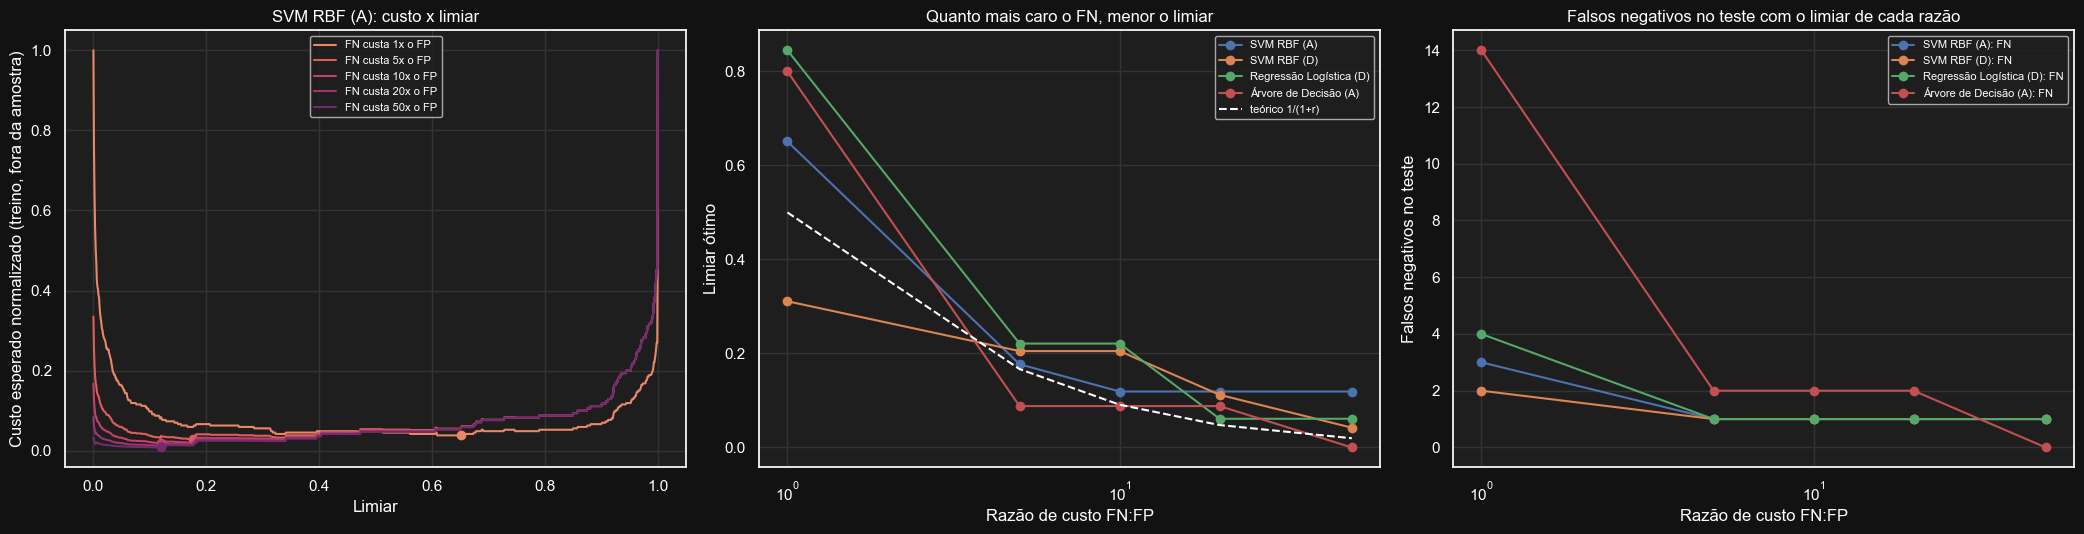

In [21]:
RAZOES = [1, 5, 10, 20, 50]
cand_t = np.linspace(0.0, 1.0, 1001)


def custo_curva(p, yy, r):
    fn = np.array([((p < t) & (yy == 1)).sum() for t in cand_t])
    fp = np.array([((p >= t) & (yy == 0)).sum() for t in cand_t])
    return (r * fn + fp) / len(yy)


linhas, t_otimo = [], {}
for k in DESTAQUE:
    for r in RAZOES:
        c = custo_curva(oof[k], y_tr, r)
        t = float(cand_t[np.where(c == c.min())[0][-1]])        # em empate, o maior limiar
        t_otimo[(k, r)] = t
        m = metricas(y_te, proba_teste[k], t)
        linhas.append({"modelo": k[0], "cenário": k[1], "razão FN:FP": r, "limiar ótimo (treino)": t,
                       "FN (teste)": m["FN"], "FP (teste)": m["FP"], "custo por 100 pacientes (teste)": 100 * (r * m["FN"] + m["FP"]) / len(y_te)})
tab_custo = pd.DataFrame(linhas)
display(tab_custo.round(3).style.hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
k0 = ("SVM RBF", "A")
for r, cor in zip(RAZOES, sns.color_palette("flare", len(RAZOES))):
    c = custo_curva(oof[k0], y_tr, r)
    axes[0].plot(cand_t, c / c.max(), color=cor, label=f"FN custa {r}x o FP")
    axes[0].plot(t_otimo[(k0, r)], c.min() / c.max(), "o", color=cor)
axes[0].set(xlabel="Limiar", ylabel="Custo esperado normalizado (treino, fora da amostra)", title="SVM RBF (A): custo x limiar"); axes[0].legend(fontsize=8)
for k in DESTAQUE:
    axes[1].plot(RAZOES, [t_otimo[(k, r)] for r in RAZOES], "o-", label=f"{k[0]} ({k[1]})")
axes[1].plot(RAZOES, [1 / (1 + r) for r in RAZOES], "w--", label="teórico 1/(1+r)")
axes[1].set(xscale="log", xlabel="Razão de custo FN:FP", ylabel="Limiar ótimo", title="Quanto mais caro o FN, menor o limiar"); axes[1].legend(fontsize=8)
for k in DESTAQUE:
    sub = tab_custo[(tab_custo["modelo"] == k[0]) & (tab_custo["cenário"] == k[1])]
    axes[2].plot(sub["razão FN:FP"], sub["FN (teste)"], "o-", label=f"{k[0]} ({k[1]}): FN")
axes[2].set(xscale="log", xlabel="Razão de custo FN:FP", ylabel="Falsos negativos no teste", title="Falsos negativos no teste com o limiar de cada razão"); axes[2].legend(fontsize=8)
plt.tight_layout()
salvar_fig(fig, "19_custo_esperado")

**Como interpretar:**
- Quanto mais caro o falso negativo, menor o limiar ideal. No SVM RBF (A): 0,65 se os erros custam igual (3 falsos negativos no teste), 0,177 com r = 5 (1 falso negativo e 2 falsos positivos) e 0,119 a partir de r = 10 (1 falso negativo e 4 falsos positivos).
- Para r pequeno, o limiar fica perto de 1/(1 + r). Para r grande ele para de baixar, porque o treino tem só 170 malignos e não dá para estimar limiares extremos.
- Passar de r = 10 para r = 50 não evita nenhum falso negativo (o caso 859983 continua perdido) e só aumenta os falsos positivos (SVM RBF no D: de 3 para 12; Regressão Logística no D: de 2 para 9).
- A Árvore mostra o extremo: com r = 50 o limiar ideal é 0 e ela classifica todos como malignos (72 falsos positivos).
- Na prática, com r entre 5 e 10, SVM RBF e Regressão Logística funcionam bem com limiares de 0,12 a 0,22.

### 9.5 O que o modelo usa para decidir

Olhamos (i) os coeficientes da Regressão Logística no cenário D, o modelo mais fácil de explicar (o "x vezes" mostra quanto as chances de maligno mudam quando o atributo sobe 1 desvio padrão); (ii) a importância dos atributos no Random Forest com os 30 atributos. Comparamos com a estatística descritiva (d de Cohen). Isso descreve o modelo, mas não prova causa.

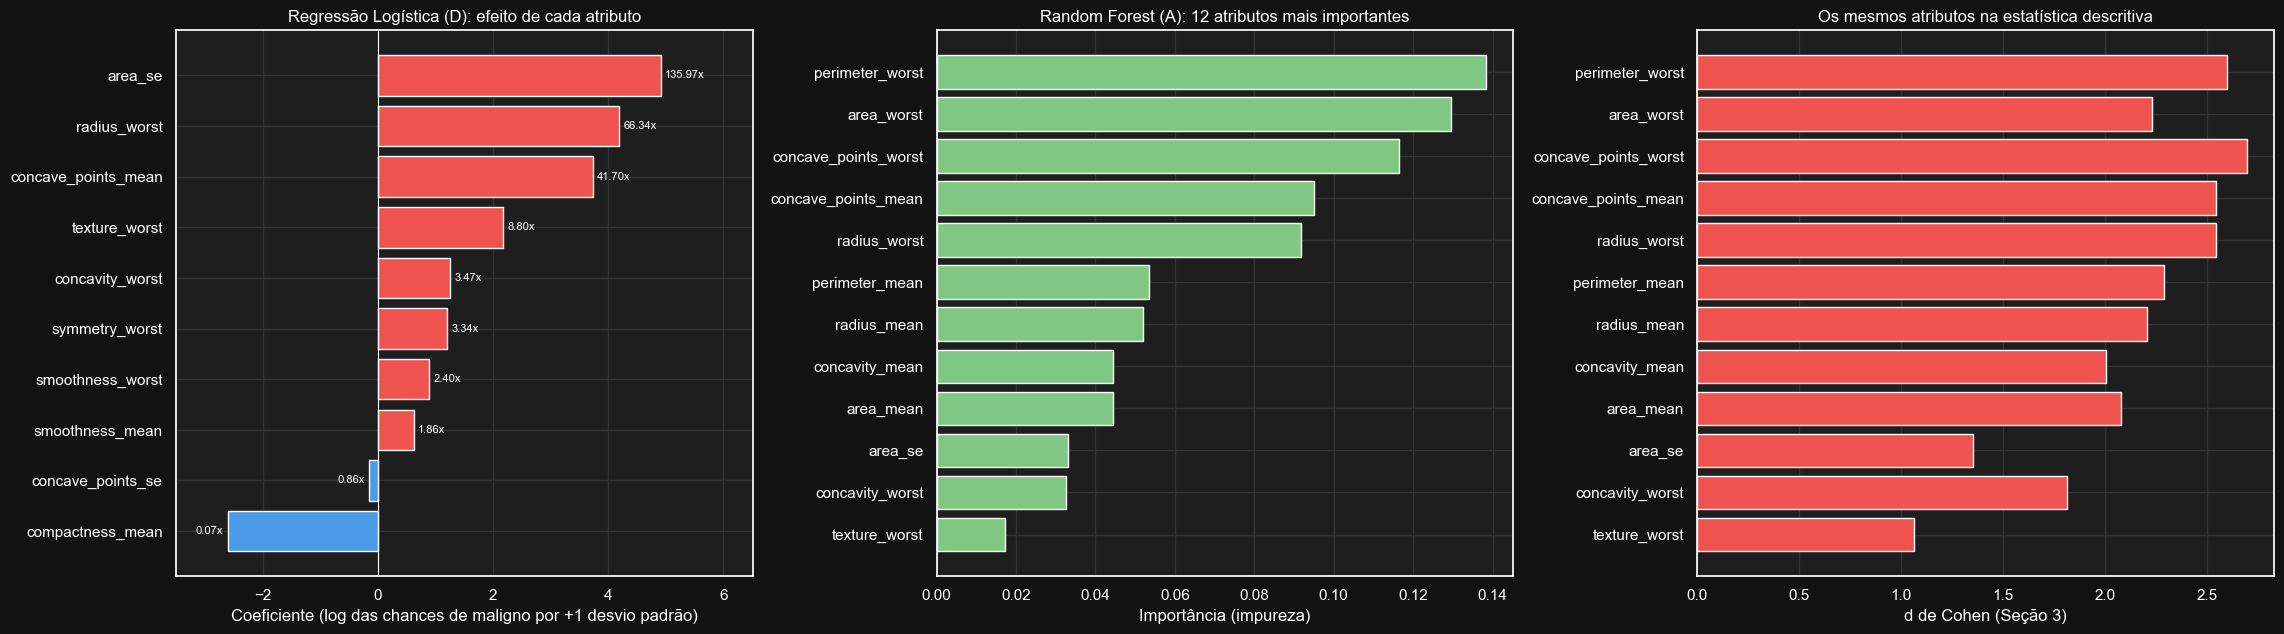

,odds ratio por +1 DP,coeficiente
area_se,135.97,4.912
radius_worst,66.34,4.195
concave_points_mean,41.70,3.731
texture_worst,8.80,2.174
concavity_worst,3.47,1.244
symmetry_worst,3.34,1.206
smoothness_worst,2.40,0.877
smoothness_mean,1.86,0.619
concave_points_se,0.86,-0.155
compactness_mean,0.07,-2.615


Importâncias do Random Forest (top 10):


,importância
perimeter_worst,0.138
area_worst,0.129
concave_points_worst,0.116
concave_points_mean,0.095
radius_worst,0.092
perimeter_mean,0.053
radius_mean,0.052
concavity_mean,0.044
area_mean,0.044
area_se,0.033


In [22]:
lr = modelos[("Regressão Logística", "D")]
nomes_d = list(lr.named_steps["top10_selecao"].transformers_[0][2])
coef = pd.Series(lr.named_steps["modelo"].coef_[0], index=nomes_d).sort_values()
rf = modelos[("Random Forest", "A")].named_steps["modelo"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(23, 6.5))
axes[0].barh(coef.index, coef.values, color=[COR_M if v > 0 else COR_B for v in coef.values])
axes[0].axvline(0, color="white", lw=0.8)
axes[0].set(xlabel="Coeficiente (log das chances de maligno por +1 desvio padrão)", title="Regressão Logística (D): efeito de cada atributo")
axes[0].set_xlim(coef.min() - 0.9, coef.max() + 1.6)
for i, (n, v) in enumerate(coef.items()):
    axes[0].text(v + (0.08 if v >= 0 else -0.08), i, f"{np.exp(v):.2f}x", va="center", ha="left" if v >= 0 else "right", fontsize=8)
top = imp.head(12)[::-1]
axes[1].barh(top.index, top.values, color="#81c784")
axes[1].set(xlabel="Importância (impureza)", title="Random Forest (A): 12 atributos mais importantes")
d_top = por_classe["d de Cohen"].loc[imp.head(12).index[::-1]]
axes[2].barh(d_top.index, d_top.values, color=COR_M)
axes[2].set(xlabel="d de Cohen (Seção 3)", title="Os mesmos atributos na estatística descritiva")
plt.tight_layout()
salvar_fig(fig, "20_interpretabilidade")
display(pd.DataFrame({"odds ratio por +1 DP": np.exp(coef)[::-1].round(2), "coeficiente": coef[::-1].round(3)}))
print("Importâncias do Random Forest (top 10):")
display(imp.head(10).round(3).to_frame("importância"))

**Como interpretar:**
- **Regressão Logística (D):** os maiores efeitos são de `area_se` (chances 136 vezes maiores), `radius_worst` (66 vezes) e `concave_points_mean` (42 vezes). O coeficiente negativo de `compactness_mean` (0,07 vezes) não quer dizer que compacidade proteja: os atributos são muito correlacionados e o coeficiente compensa os outros. Com atributos correlacionados, vale olhar o conjunto e não cada coeficiente separado.
- **Random Forest (A):** os 5 mais importantes são `perimeter_worst` (0,138), `area_worst` (0,129), `concave_points_worst` (0,116), `concave_points_mean` (0,095) e `radius_worst` (0,092), cerca de 57% do total. Como raio, perímetro e área são redundantes, a importância se divide entre eles.
- Os atributos mais importantes são os mesmos de maior d de Cohen (Seção 3) e os da seleção (Seção 6). O que mais pesa é o **tamanho dos núcleos** e a **irregularidade do contorno**, com textura e suavidade ajudando um pouco. Isso faz sentido: núcleos de células malignas são maiores e mais irregulares.

### 9.6 Limitações e trabalhos futuros

**Limitações**
- Só 569 pacientes, de uma instituição (Wisconsin, anos 1990). Não sabemos se funciona em outras populações, e não houve validação externa.
- Os 30 atributos já vêm calculados a partir das imagens. Não partimos da imagem original.
- O teste tem só 42 malignos: os intervalos são largos, e diferenças de 1 a 3 pacientes entre modelos não são conclusivas. Os resultados também dependem de uma única divisão treino/teste. A validação cruzada repetida do Vitor ajuda nesse ponto.
- O Top-10 e os hiperparâmetros foram escolhidos com todo o treino, então a validação cruzada do cenário D é um pouco otimista (dá para ver no KNN e na Árvore).
- As probabilidades de alguns modelos (SVM, KNN, Naive Bayes e Árvore) não são probabilidades "de verdade", e o limiar foi escolhido com só 170 malignos.
- Uma paciente (ID 859983) é classificada como benigna por todos os 28 modelos. Os 30 atributos não bastam para ela, e não sabemos o motivo.
- Não usamos dados clínicos (idade, histórico, mamografia). O modelo é um apoio à decisão e não substitui o especialista nem a biópsia.

**O que pode melhorar**
1. Validar com dados de outras instituições.
2. Usar validação cruzada aninhada para escolher cenário, hiperparâmetros e limiar sem otimismo.
3. Calibrar as probabilidades e checar a calibração.
4. Dar mais peso aos cânceres no treino (aprendizado sensível a custo) e encaminhar ao especialista os casos de probabilidade intermediária.
5. Combinar vários modelos (ensembles).
6. Explicar cada decisão individualmente, mostrando quais medidas pesaram em cada paciente.
7. Usar as imagens diretamente (redes neurais convolucionais) junto com dados clínicos.

## 10. Sumário e conclusões

### 10.1 Resumo visual dos resultados

O painel mostra a curva ROC (com zoom), a sensibilidade com intervalo de 95% e os erros antes e depois do ajuste do limiar.

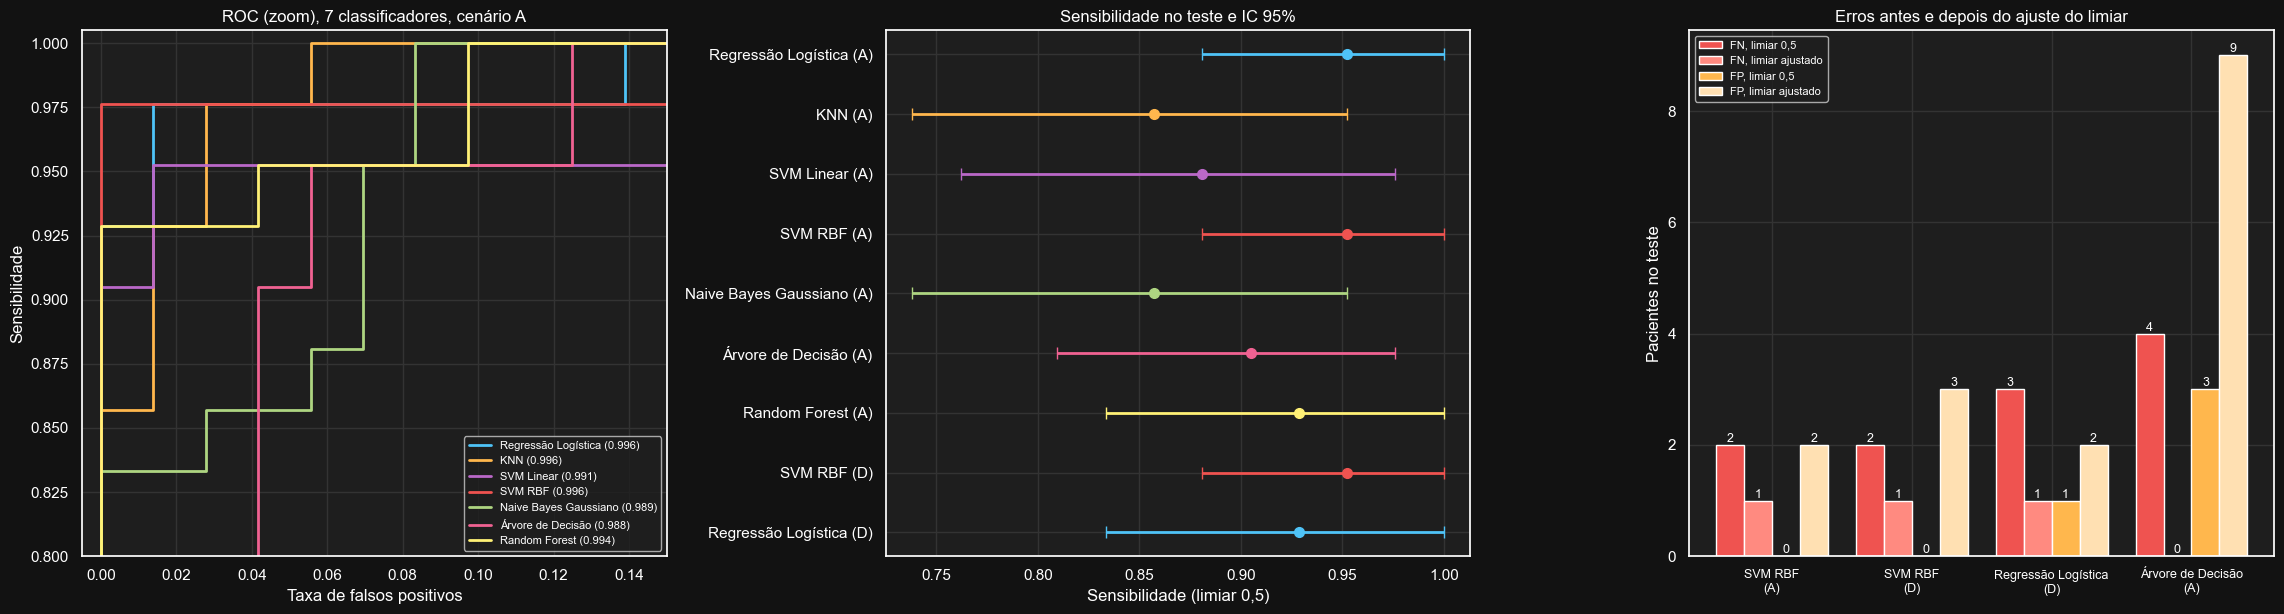

In [23]:
# Painel final: ROC (zoom), sensibilidade com IC e erros antes/depois do ajuste do limiar
fig, axes = plt.subplots(1, 3, figsize=(23, 6.3))
for mod in MODELOS:
    fpr, tpr, _ = roc_curve(y_te, proba_teste[(mod, "A")])
    axes[0].plot(fpr, tpr, color=CORES_MOD[mod], lw=2, drawstyle="steps-post", label=f"{mod} ({roc_auc_score(y_te, proba_teste[(mod, 'A')]):.3f})")
axes[0].set(xlim=(-0.005, 0.15), ylim=(0.80, 1.005), xlabel="Taxa de falsos positivos", ylabel="Sensibilidade", title="ROC (zoom), 7 classificadores, cenário A")
axes[0].legend(fontsize=8, loc="lower right")

for i, k in enumerate(CHAVES_IC):
    b = res_teste[(res_teste["modelo"] == k[0]) & (res_teste["cenário"] == k[1])].iloc[0]["Sensibilidade"]
    lo, hi = ic[k]["Sensibilidade"]
    axes[1].errorbar(b, i, xerr=[[b - lo], [hi - b]], fmt="o", color=CORES_MOD[k[0]], capsize=4, lw=2, ms=7)
axes[1].set_yticks(range(len(CHAVES_IC)), rotulo_k); axes[1].invert_yaxis()
axes[1].set(xlabel="Sensibilidade (limiar 0,5)", title="Sensibilidade no teste e IC 95%")

x = np.arange(len(DESTAQUE)); larg = 0.2
fn0 = [metricas(y_te, proba_teste[k], 0.5)["FN"] for k in DESTAQUE]; fp0 = [metricas(y_te, proba_teste[k], 0.5)["FP"] for k in DESTAQUE]
fn1 = [metricas(y_te, proba_teste[k], LIM_ESC[k])["FN"] for k in DESTAQUE]; fp1 = [metricas(y_te, proba_teste[k], LIM_ESC[k])["FP"] for k in DESTAQUE]
for off, val, cor, nome in [(-1.5, fn0, COR_M, "FN, limiar 0,5"), (-0.5, fn1, "#ff8a80", "FN, limiar ajustado"),
                            (0.5, fp0, "#ffb74d", "FP, limiar 0,5"), (1.5, fp1, "#ffe0b2", "FP, limiar ajustado")]:
    barras = axes[2].bar(x + off * larg, val, larg, color=cor, label=nome)
    axes[2].bar_label(barras, fontsize=9)
axes[2].set_xticks(x, [f"{m}\n({c})" for m, c in DESTAQUE], fontsize=9)
axes[2].set(ylabel="Pacientes no teste", title="Erros antes e depois do ajuste do limiar"); axes[2].legend(fontsize=8)
plt.tight_layout()
salvar_fig(fig, "21_sintese_visual")

### 10.2 Sumário

**Pergunta.** Dá para prever se uma lesão de mama é maligna ou benigna a partir das medidas das células, errando o mínimo possível nos falsos negativos?

**Dados.** Base WDBC: 569 pacientes (212 malignas e 357 benignas) e 30 medidas dos núcleos das células, sem valores faltantes nem duplicatas. Tiramos o `id`, codificamos o diagnóstico (0 = benigno, 1 = maligno) e dividimos em treino e teste (455 e 114) antes de qualquer ajuste, com as transformações dentro de *pipelines*.

**O que vimos nos dados.** Os tumores malignos têm núcleos maiores e mais irregulares. Os atributos que mais diferenciam são `concave_points_worst`, `perimeter_worst`, `concave_points_mean` e `radius_worst` (d de Cohen de 2,5 a 2,7). Há muita correlação entre atributos (21 pares com |r| > 0,90). Sem usar o diagnóstico, K-Means e GMM já concordam com ele em 91% e 93% dos pacientes.

**Modelos.** Testamos 7 classificadores em 4 cenários (30 atributos, PCA, `SelectKBest` e Top-10), com validação cruzada de 10 partes e busca de hiperparâmetros. Na validação cruzada, a ROC-AUC fica entre 0,96 e 0,997, e não há diferença significativa entre os melhores.

**Resultado no teste** (uma única avaliação, limiar 0,5, cenário A):

| Modelo | ROC-AUC | Sensibilidade | Especificidade | FN | FP |
| :--- | :---: | :---: | :---: | :---: | :---: |
| SVM RBF | 0,996 | 95,2% (40/42) | 100% (72/72) | 2 | 0 |
| Regressão Logística | 0,996 | 95,2% (40/42) | 98,6% (71/72) | 2 | 1 |
| Random Forest | 0,994 | 92,9% (39/42) | 100% (72/72) | 3 | 0 |
| Árvore de Decisão | 0,988 | 90,5% (38/42) | 95,8% (69/72) | 4 | 3 |
| SVM Linear | 0,991 | 88,1% (37/42) | 100% (72/72) | 5 | 0 |
| KNN | 0,996 | 85,7% (36/42) | 100% (72/72) | 6 | 0 |
| Naive Bayes | 0,989 | 85,7% (36/42) | 95,8% (69/72) | 6 | 3 |

- A ROC-AUC é de 0,99 ou perto disso em todos os modelos (a menor é a da Árvore, 0,988), mas a sensibilidade vai de 85,7% a 95,2%. Os intervalos de confiança são largos (por exemplo, [0,881; 1,000] para o SVM RBF).
- Reduzir de 30 para 10 atributos (cenário D) não piora Regressão Logística, SVMs e Random Forest.
- Ajustando o limiar só com dados de treino (sensibilidade de pelo menos 98%), o SVM RBF (A) vai de 95,2% para **97,6% (41 de 42)** de sensibilidade, com especificidade de 97,2% (70 de 72). Na Regressão Logística (D), os falsos negativos caem de 3 para 1, com 2 falsos positivos.
- Os erros que sobram vêm dos dados: a paciente de ID 859983 é classificada como benigna pelos 28 modelos.
- O que mais pesa na decisão é o tamanho dos núcleos e a irregularidade do contorno, o que faz sentido clinicamente.

**Limitações.** Amostra pequena e de uma só instituição, sem validação externa; teste com só 42 malignos; atributos já calculados; probabilidades não calibradas. Os próximos passos estão na Seção 9.6.

### 10.3 Conclusão

**A hipótese se confirma na capacidade de separar as classes e se confirma com ressalvas na redução dos falsos negativos.** Vários modelos de tipos diferentes chegam a ROC-AUC de 0,99 ou mais e a acurácia de 92% a 98% no teste. Mas, com o limiar 0,5, eles deixam passar de 2 a 6 dos 42 cânceres. Ajustando o limiar com o treino, o melhor resultado dos modelos recomendados é **1 falso negativo em 42 cânceres (sensibilidade de 97,6%), com 2 ou 3 falsos positivos em 72 benignos**. É um bom acordo quando o falso negativo é o erro mais grave. Não chegamos a 100%: pelo menos uma paciente não se distingue de um caso benigno com esses atributos, então o especialista continua sendo necessário.

**Recomendação do grupo:** SVM RBF (30 atributos, ou Top-10 se quisermos um modelo mais simples) com o limiar ajustado pelo treino, e Regressão Logística com Top-10 como opção fácil de explicar. Sempre como apoio à decisão e só depois de validar com dados de outras instituições.